# 10. Bộ Đánh Giá Baseline Propensity Đa Tầng & Kiểm Chứng Out-of-Client (`H=1` & `H=3`)

Notebook tổng hợp trọn vẹn hệ thống baseline đa tầng cho bài toán dự báo xác suất mua ít nhất một trong bốn sản phẩm (`y_any`) trên bộ dữ liệu ngân hàng doanh nghiệp **MBD-mini** (`100.224` khách hàng × `12` tháng nhãn `02/2022–01/2023`), thiết kế bám sát khung đánh giá chuẩn:

1. **Tầng Non-ML**:
   - `T0_random_prevalence`: mốc sàn base rate (`p_train`) + phá hòa tất định `SHA-256(seed=42, client_id)`.
   - `T1a_rule_rf`: luật RF cổ điển 2 biến (`trx_84d_event_count` & `trx_84d_days_since_last_event`).
   - `T1b_rule_eda_scorecard`: luật nghiệp vụ phi-ML mạnh hơn xây từ insight EDA (`prior_3m_buy_months` + `dialog_30d` + RFM) — đại diện cho **baseline business thực tế cần vượt**.
2. **Tầng ML đơn giản & GBDT mặc định trên feature thô (chưa FE)**:
   - `T2_logreg_simple10`: L2 Logistic Regression (`C=1.0`, fit imputer/scaler riêng trên train) trên **10 biến cơ bản, dễ diễn giải**.
   - `T2b_logreg_top50`: L2 Logistic Regression trên **50 biến sau FE** để đo đóng góp của FE ngay trên mô hình tuyến tính.
   - `T3a_lgbm_default_raw203` & `T3b_xgb_default_raw203`: **LightGBM** & **XGBoost tham số mặc định** trên **203 biến thô sạch** (đã loại 18 cột thời gian ẩn, chưa có `prior_purchase` & 14 biến dẫn xuất FE).
   - `T4a_lgbm_default_top50` & `T4b_xgb_default_top50`: **LightGBM** & **XGBoost tham số mặc định** trên **50 biến sau FE** — tách bạch chính xác giá trị thuần của Feature Engineering (cùng thuật toán, cùng tham số mặc định).
3. **Tầng Mô hình cuối & Hiệu chỉnh xác suất**:
   - `T5_final_catboost_top50`: CatBoost regularized (`iterations=400, lr=0.05, depth=6, l2_leaf_reg=10, rsm=0.6`, giữ nguyên `NaN` có ngữ nghĩa, **không SMOTE/resample**).
   - `T5_final_cal_intercept` & `T5_final_cal_platt` (cho `H=1` Final): hiệu chỉnh hậu kỳ đơn điệu fit nghiêm ngặt trên tháng `2022-12` (bảo toàn 100% thứ hạng).
4. **Thiết kế đánh giá chống rò rỉ & Kiểm chứng 0% trùng khách (`Out-of-Time + Out-of-Client`)**:
   - **Out-of-Time (OOT)** với `3` tháng burn-in (`02–04/2022`), embargo cứng `2` tháng cho `H=3` ($s_{\max} \le T_{\text{eval}} - 3$), xử lý rõ hiện tượng `B0` pooled `AUC = 0,5179` bằng đối chiếu theo từng tháng & Holdout khóa cứng.
   - **Kiểm chứng 5-fold `OOT + OOC` (0% trùng `client_id` giữa train và test)** tận dụng cột phân chia chính thức `client_split/fold=0..4` của MBD-mini trên trọn bộ `100.224` khách hàng.
   - **Đầy đủ metric**: `PR-AUC (AP)`, `ROC-AUC`, `Lift/Recall/Precision@K` tại các mốc ngân sách campaign **`0,5%`, `1%` (chính), `5%`**, **`Brier Score` & `Brier Skill Score`**, `Log Loss`, `ECE`, `Reliability Curve` cùng **1.000 lần Client-Clustered Bootstrap 95% CI & Paired Bootstrap p-value**.


## 1. Xác thực Hợp đồng Dữ liệu, Phân tích Missingness & Kiểm tra Chống Rò Rỉ


In [1]:
import json
from pathlib import Path

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_curve, roc_curve

plt.rcParams.update({
    "figure.dpi": 135,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 9.5,
})

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "processed").exists():
    REPO_ROOT = REPO_ROOT.parent

RUN_DIR = REPO_ROOT / "outputs" / "baseline_ladder_v1"
METRIC_DIR = RUN_DIR / "metrics"
PRED_DIR = RUN_DIR / "predictions"
FIG_DIR = RUN_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

manifest = json.loads((RUN_DIR / "manifest.json").read_text(encoding="utf-8"))
assert manifest["status"] == "ready", f"Run not ready: {manifest}"

val_monthly = pd.read_csv(METRIC_DIR / "val_monthly_metrics.csv")
final_df = pd.read_csv(METRIC_DIR / "final_holdout_metrics.csv")
boot_df = pd.read_csv(METRIC_DIR / "bootstrap_summary.csv")
paired_df = pd.read_csv(METRIC_DIR / "paired_bootstrap.csv")
cal_bins = pd.read_csv(METRIC_DIR / "calibration_bins.csv")
ooc_df = pd.read_csv(METRIC_DIR / "ooc_holdout_metrics.csv")
ooc_cmp = pd.read_csv(METRIC_DIR / "ooc_vs_panel_comparison.csv")

print(f"Seed                     : {manifest['seed']}")
print(f"Bootstrap replicates     : {manifest['bootstrap_replicates']:,} (client-clustered)")
print(f"Campaign budgets         : {[f'{b*100:g}%' for b in manifest['budget_fractions']]} (primary: {manifest['primary_budget']*100:g}%)")
print(f"Burn-in months           : {manifest['burn_in_months']}")
print(f"Feature counts           : {manifest['feature_counts']}")
print(f"Versions                 : LightGBM {manifest['versions']['lightgbm']} | XGBoost {manifest['versions']['xgboost']}")
print(f"Total benchmark runtime  : {manifest['elapsed_seconds']:.1f}s")

# Verify client_split fold partition & missingness profile on the enriched panel
enriched_path = (RUN_DIR / "enriched_panel.parquet").as_posix()
folds_path = (RUN_DIR / "client_folds.parquet").as_posix()
with duckdb.connect() as con:
    fold_check = con.execute(f'''
        SELECT f.fold,
               COUNT(DISTINCT f.client_id) AS n_clients,
               COUNT(*) AS n_panel_rows,
               ROUND(100.0 * AVG(CASE WHEN p.month='2023-01' THEN p.y_h1 END), 3) AS h1_jan23_prev_pct,
               ROUND(100.0 * AVG(CASE WHEN p.month='2022-11' THEN p.y_h3 END), 3) AS h3_nov22_prev_pct
        FROM read_parquet('{enriched_path}') p
        JOIN read_parquet('{folds_path}') f USING (client_id)
        GROUP BY 1 ORDER BY 1
    ''').fetch_df()
    # Missingness summary on SIMPLE10 features (modeling months 2022-05..2023-01)
    simple10 = manifest["simple10_features"]
    miss_expr = ", ".join(f'ROUND(100.0 * AVG(CASE WHEN {c} IS NULL THEN 1.0 ELSE 0.0 END), 2) AS "{c}"' for c in simple10)
    miss_s = con.execute(f"SELECT {miss_expr} FROM read_parquet('{enriched_path}')").fetch_df().T
    miss_s.columns = ["missing_pct"]
    miss_s.index.name = "feature"

print("\nPhân bổ 5-fold tách rời theo client_id (0% trùng khách giữa các fold):")
display(fold_check)
print("\nTỷ lệ giá trị khuyết (NULL) có ngữ nghĩa trên bộ 10 biến cơ bản (SIMPLE10):")
display(miss_s)


Seed                     : 42
Bootstrap replicates     : 1,000 (client-clustered)
Campaign budgets         : ['0.5%', '1%', '5%'] (primary: 1%)
Burn-in months           : ['2022-02', '2022-03', '2022-04']
Feature counts           : {'none': 0, 'heuristic_rf': 2, 'rule_eda': 5, 'simple10': 10, 'raw_clean_203': 203, 'top50': 50}
Versions                 : LightGBM 4.7.0 | XGBoost 3.4.1
Total benchmark runtime  : 3272.4s



Phân bổ 5-fold tách rời theo client_id (0% trùng khách giữa các fold):


,fold,n_clients,n_panel_rows,h1_jan23_prev_pct,h3_nov22_prev_pct
0,0,20328,182952,0.703,2.248
1,1,19902,179118,0.643,2.080
2,2,19917,179253,0.643,2.274
3,3,20017,180153,0.679,2.163
4,4,20060,180540,0.698,2.074



Tỷ lệ giá trị khuyết (NULL) có ngữ nghĩa trên bộ 10 biến cơ bản (SIMPLE10):


,missing_pct
feature,
trx_84d_event_count,0.00
trx_84d_days_since_last_event,15.36
trx_84d_log1p_main_amount_abs_sum,15.36
trx_all_days_since_first_recorded_event,5.75
trx_30d_event_type_nunique,0.00
dialog_30d_has_event,0.00
dialog_84d_event_count,0.00
geo_30d_geohash_4_nunique,0.00
prior_3m_buy_months,0.00


**Nhận xét mục 1 (Hợp đồng dữ liệu & Xử lý Missingness):**
- Toàn bộ `100.224` khách hàng khớp 1-1 vào `5` fold độc lập (`19.902–20.328` khách/fold, **0% trùng `client_id` giữa các fold**) với tỷ lệ dương rất đồng đều trên cả Holdout `H=1` (`2023-01`: `0,643%–0,703%`) và `H=3` (`2022-11`: `2,074%–2,274%`). Đây là nền tảng chuẩn xác cho kiểm chứng **Out-of-Time + Out-of-Client (`OOT + OOC`)** ở Mục 6.
- Các giá trị `NULL` hoàn toàn **mang ngữ nghĩa nghiệp vụ** (không phải lỗi dữ liệu): `trx_84d_days_since_last_event` và `trx_84d_log1p_main_amount_abs_sum` trống đúng **`15,36%`** ứng với khách không phát sinh giao dịch trong 84 ngày; `trx_all_days_since_first_recorded_event` trống **`5,75%`** ứng với nhóm chưa từng có lịch sử giao dịch từ `2021` (7 biến còn lại đầy đủ `100%`). Do đó:
  - **Mô hình cây (`LightGBM`, `XGBoost`, `CatBoost`)**: giữ nguyên `NaN` tự nhiên để cây học nhánh rẽ trực tiếp.
  - **Mô hình tuyến tính (`Logistic Regression`)**: fit `SimpleImputer(strategy="median", add_indicator=True)` + `StandardScaler()` **nghiêm ngặt chỉ trên tập train từng fold** (tránh data leakage và vẫn bảo toàn cờ báo missing).
- Trên bộ dữ liệu thô (`221` biến gốc), `18` cột thời gian ẩn (`*_source_window_overlap_days`, `*_history_truncated`) đã được loại chủ động để tạo bộ **`raw_clean_203` (`203` biến thô sạch, chưa có `prior_purchase` và `14` biến dẫn xuất FE)**.


## 2. Chẩn đoán Hiện tượng `B0` Pooled `AUC = 0,5179` & Biến động Base Rate Theo Thời Gian


T0_random_prevalence theo TỪNG THÁNG (ROC-AUC luôn đúng 0.5000, AP luôn đúng = prevalence):


,horizon,eval_month,positives,prevalence,average_precision,roc_auc,lift_1pct,brier,calibration_ratio
0,1,2022-09,1013,0.010107,0.010107,0.5,1.479628,0.010006,1.077493
1,1,2022-10,868,0.008661,0.008661,0.5,1.151201,0.008590,1.239401
2,1,2022-11,867,0.008651,0.008651,0.5,0.576264,0.008579,1.200884
30,3,2022-08,2849,0.028426,0.028426,0.5,1.157423,0.027621,1.055107
31,3,2022-09,2610,0.026042,0.026042,0.5,1.110269,0.025382,1.163410
32,3,2022-10,2369,0.023637,0.023637,0.5,1.181038,0.023118,1.265935



T0_random_prevalence khi GỘP 3 THÁNG (Pooled Validation — xuất hiện tín hiệu thời gian giả từ p_train):


,horizon,average_precision,roc_auc,roc_auc_ci_low,roc_auc_ci_high,lift_1pct,brier
0,1,0.009574,0.517873,0.506820,0.528034,1.018828,0.009058
10,3,0.026474,0.510537,0.507036,0.513724,1.034651,0.025373


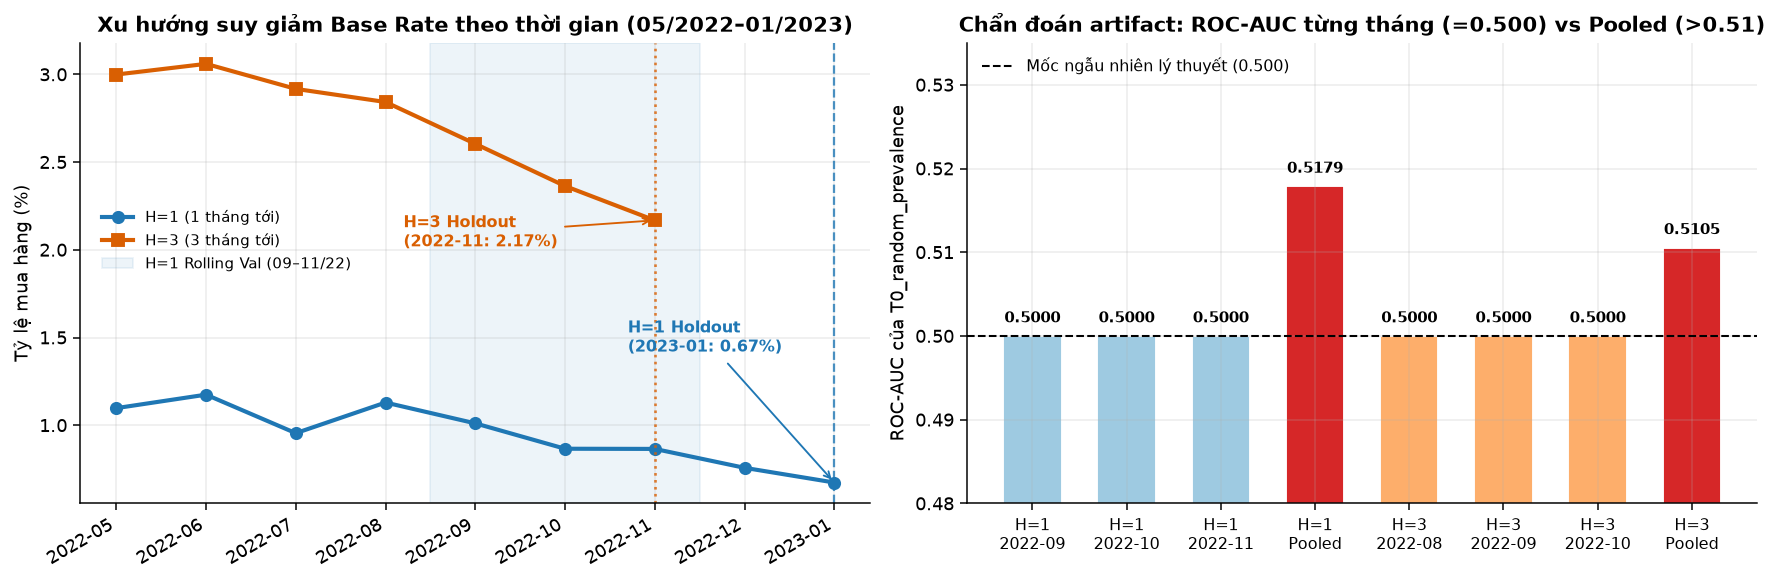

In [2]:
# Compare per-month vs pooled metrics for T0_random_prevalence
b0_monthly = val_monthly[val_monthly["tier_id"] == "T0_random_prevalence"][
    ["horizon", "eval_month", "positives", "prevalence", "average_precision", "roc_auc", "lift_1pct", "brier", "calibration_ratio"]
].copy()
b0_pooled = boot_df[(boot_df["scope"] == "validation_pooled") & (boot_df["tier_id"] == "T0_random_prevalence")][
    ["horizon", "average_precision", "roc_auc", "roc_auc_ci_low", "roc_auc_ci_high", "lift_1pct", "brier"]
].copy()

print("T0_random_prevalence theo TỪNG THÁNG (ROC-AUC luôn đúng 0.5000, AP luôn đúng = prevalence):")
display(b0_monthly)
print("\nT0_random_prevalence khi GỘP 3 THÁNG (Pooled Validation — xuất hiện tín hiệu thời gian giả từ p_train):")
display(b0_pooled)

# Plot prevalence drift + B0 per-month vs pooled AUC
with duckdb.connect() as con:
    prev_ts = con.execute(f'''
        SELECT month,
               100.0 * AVG(y_h1) AS prev_h1_pct,
               100.0 * AVG(y_h3) AS prev_h3_pct
        FROM read_parquet('{enriched_path}')
        GROUP BY 1 ORDER BY 1
    ''').fetch_df()

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.4))

# Left: Monthly prevalence drift
ax = axes[0]
x = np.arange(len(prev_ts))
ax.plot(x, prev_ts["prev_h1_pct"], marker="o", lw=2.2, color="#1f77b4", label="H=1 (1 tháng tới)")
ax.plot(x, prev_ts["prev_h3_pct"], marker="s", lw=2.2, color="#d95f02", label="H=3 (3 tháng tới)")
ax.axvspan(3.5, 6.5, color="#1f77b4", alpha=0.08, label="H=1 Rolling Val (09–11/22)")
ax.axvline(8, color="#1f77b4", ls="--", lw=1.2, alpha=0.8)
ax.axvline(6, color="#d95f02", ls=":", lw=1.4, alpha=0.8)
ax.annotate("H=1 Holdout\n(2023-01: 0.67%)", xy=(8, prev_ts["prev_h1_pct"].iloc[8]),
            xytext=(5.7, 1.42), arrowprops=dict(arrowstyle="->", color="#1f77b4"), fontsize=8.5, color="#1f77b4", fontweight="bold")
ax.annotate("H=3 Holdout\n(2022-11: 2.17%)", xy=(6, prev_ts["prev_h3_pct"].iloc[6]),
            xytext=(3.2, 2.02), arrowprops=dict(arrowstyle="->", color="#d95f02"), fontsize=8.5, color="#d95f02", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(prev_ts["month"], rotation=30, ha="right")
ax.set_ylabel("Tỷ lệ mua hàng (%)")
ax.set_title("Xu hướng suy giảm Base Rate theo thời gian (05/2022–01/2023)", fontweight="bold")
ax.legend(frameon=False, fontsize=8.2, loc="center left", bbox_to_anchor=(0.01, 0.57))

# Right: B0 per-month AUC vs Pooled AUC artifact
ax2 = axes[1]
labels = ["H=1\n2022-09", "H=1\n2022-10", "H=1\n2022-11", "H=1\nPooled", "H=3\n2022-08", "H=3\n2022-09", "H=3\n2022-10", "H=3\nPooled"]
aucs = [0.5, 0.5, 0.5, float(b0_pooled[b0_pooled["horizon"] == 1]["roc_auc"].iloc[0]),
        0.5, 0.5, 0.5, float(b0_pooled[b0_pooled["horizon"] == 3]["roc_auc"].iloc[0])]
colors = ["#9ecae1", "#9ecae1", "#9ecae1", "#d62728", "#fdae6b", "#fdae6b", "#fdae6b", "#d62728"]
bars = ax2.bar(np.arange(len(labels)), aucs, color=colors, width=0.62, edgecolor="white")
ax2.axhline(0.5, color="black", ls="--", lw=1.1, label="Mốc ngẫu nhiên lý thuyết (0.500)")
ax2.set_ylim(0.48, 0.535)
ax2.set_xticks(np.arange(len(labels)))
ax2.set_xticklabels(labels, fontsize=8.3)
ax2.set_ylabel("ROC-AUC của T0_random_prevalence")
ax2.set_title("Chẩn đoán artifact: ROC-AUC từng tháng (=0.500) vs Pooled (>0.51)", fontweight="bold")
for bar, v in zip(bars, aucs):
    ax2.text(bar.get_x() + bar.get_width() / 2, v + 0.0012, f"{v:.4f}", ha="center", va="bottom", fontsize=8, fontweight="bold")
ax2.legend(frameon=False, fontsize=8.5, loc="upper left")

fig.tight_layout()
fig.savefig(FIG_DIR / "01_prevalence_drift_and_b0_artifact.png", dpi=150, bbox_inches="tight")
plt.show()


**Nhận xét mục 2 (Tại sao `B0` pooled ra `AUC = 0,5179` và cách báo cáo chuẩn):**
- Trong **mọi tháng đơn lẻ** (`09, 10, 11/2022` cho `H=1`; `08, 09, 10/2022` cho `H=3`; và trên cả 2 tháng Holdout `2023-01` & `2022-11`), `T0_random_prevalence` đều đạt chính xác **`ROC-AUC = 0,5000`** và **`PR-AUC = prevalence`**.
- Lý do bản báo cáo gộp 3 tháng (`validation_pooled`) trước đây cho `AUC = 0,5179` (`H=1`) và `0,5105` (`H=3`) là do **base rate thực tế giảm dần theo thời gian** (`H=1`: `1,01% → 0,87% → 0,67%`; `H=3`: `2,84% → 2,60% → 2,36% → 2,17%`), kéo theo `p_train` của mỗi fold giảm tương ứng. Khi gộp chung 3 tháng để xếp hạng, hằng số `p_train` khác nhau giữa các tháng tạo ra một tín hiệu lịch giả.
- **Quy ước khắc phục trong notebook này:**
  1. Ở Rolling Validation, báo cáo **trung bình theo từng tháng (Macro-Monthly Mean ± SD)** song song với Pooled CI.
  2. Lấy **Final Locked Holdout đơn tháng (`2023-01` cho `H=1` và `2022-11` cho `H=3`)** với đầy đủ tất cả các tầng (`T0 → T5`) và **1.000 lần bootstrap CI** làm bảng đối chứng chuẩn không bị nhiễu gộp tháng.


## 3. Bậc Thang Baseline Đa Tầng (`T0 → T5`): Rolling Validation & Final Holdout


In [3]:
TIER_ORDER = [
    "T0_random_prevalence",
    "T1a_rule_rf",
    "T1b_rule_eda_scorecard",
    "T2_logreg_simple10",
    "T2b_logreg_top50",
    "T3a_lgbm_default_raw203",
    "T3b_xgb_default_raw203",
    "T4a_lgbm_default_top50",
    "T4b_xgb_default_top50",
    "T5_final_catboost_top50",
    "T5_final_cal_intercept",
]

def fmt_ci(val, lo, hi, digits=4, suffix=""):
    if pd.isna(val):
        return "—"
    return f"{val:.{digits}f}{suffix} [{lo:.{digits}f}, {hi:.{digits}f}]"

def build_holdout_report_table(h: int) -> pd.DataFrame:
    f_sub = final_df[final_df["horizon"] == h].set_index("tier_id")
    b_sub = boot_df[(boot_df["horizon"] == h) & (boot_df["scope"] == "final_holdout_panel")].set_index("tier_id")
    rows = []
    for tid in TIER_ORDER:
        if tid not in f_sub.index:
            continue
        r = f_sub.loc[tid]
        b = b_sub.loc[tid]
        rows.append({
            "Tầng": r["tier_group"],
            "Mô hình": tid,
            "Feature Set (#)": f"{r['feature_set']} ({int(r['n_features'])})",
            "PR-AUC (95% CI)": fmt_ci(b["average_precision"], b["average_precision_ci_low"], b["average_precision_ci_high"], 4),
            "ROC-AUC (95% CI)": fmt_ci(b["roc_auc"], b["roc_auc_ci_low"], b["roc_auc_ci_high"], 4),
            "Lift@1% (95% CI)": fmt_ci(b["lift_1pct"], b["lift_1pct_ci_low"], b["lift_1pct_ci_high"], 2, "×"),
            "Recall@1%": f"{r['recall_1pct']*100:.2f}%",
            "Prec@1%": f"{r['precision_1pct']*100:.2f}%",
            "Lift@5%": f"{r['lift_5pct']:.2f}×",
            "Brier (95% CI)": fmt_ci(b["brier"], b["brier_ci_low"], b["brier_ci_high"], 5),
            "BSS": "—" if pd.isna(r["brier_skill"]) else f"{r['brier_skill']*100:+.2f}%",
            "LogLoss": "—" if pd.isna(r["log_loss"]) else f"{r['log_loss']:.5f}",
        })
    return pd.DataFrame(rows)

print("=== BẢNG 3A — FINAL LOCKED HOLDOUT H=1 (Test 2023-01 | Train 2022-05..11 | 100.224 khách, 675 dương, base rate 0,67%) ===")
display(build_holdout_report_table(1))

print("\n=== BẢNG 3B — FINAL LOCKED HOLDOUT H=3 (Test 2022-11 | Train 2022-05..08, embargo 2m | 100.224 khách, 2.173 dương, base rate 2,17%) ===")
display(build_holdout_report_table(3))

# Also show Macro-Average Rolling Validation (exact per-month mean across 3 folds)
macro_val = (
    val_monthly.groupby(["horizon", "tier_id"], as_index=False)
    .agg(
        ap_mean=("average_precision", "mean"),
        ap_std=("average_precision", "std"),
        auc_mean=("roc_auc", "mean"),
        auc_std=("roc_auc", "std"),
        lift1_mean=("lift_1pct", "mean"),
        lift1_std=("lift_1pct", "std"),
        brier_mean=("brier", "mean"),
        bss_mean=("brier_skill", "mean"),
    )
)
order_map = {t: i for i, t in enumerate(TIER_ORDER)}
macro_val["ord"] = macro_val["tier_id"].map(order_map)
macro_val = macro_val.sort_values(["horizon", "ord"]).drop(columns="ord")
print("\n=== BẢNG 3C — ROLLING OOT VALIDATION (Trung bình theo từng tháng ± SD qua 3 fold, loại nhiễu gộp tháng) ===")
for h in (1, 3):
    sub = macro_val[macro_val["horizon"] == h].copy()
    sub["PR-AUC (mean±sd)"] = sub.apply(lambda r: f"{r['ap_mean']:.4f} ± {r['ap_std']:.4f}", axis=1)
    sub["ROC-AUC (mean±sd)"] = sub.apply(lambda r: f"{r['auc_mean']:.4f} ± {r['auc_std']:.4f}", axis=1)
    sub["Lift@1% (mean±sd)"] = sub.apply(lambda r: f"{r['lift1_mean']:.2f}× ± {r['lift1_std']:.2f}", axis=1)
    sub["Brier (mean)"] = sub["brier_mean"].map(lambda v: "—" if pd.isna(v) else f"{v:.5f}")
    sub["BSS (mean)"] = sub["bss_mean"].map(lambda v: "—" if pd.isna(v) else f"{v*100:+.2f}%")
    print(f"\n--- H={h} Rolling Validation (3 folds) ---")
    display(sub[["tier_id", "PR-AUC (mean±sd)", "ROC-AUC (mean±sd)", "Lift@1% (mean±sd)", "Brier (mean)", "BSS (mean)"]])


=== BẢNG 3A — FINAL LOCKED HOLDOUT H=1 (Test 2023-01 | Train 2022-05..11 | 100.224 khách, 675 dương, base rate 0,67%) ===


,Tầng,Mô hình,Feature Set (#),PR-AUC (95% CI),ROC-AUC (95% CI),Lift@1% (95% CI),Recall@1%,Prec@1%,Lift@5%,Brier (95% CI),BSS,LogLoss
0,0. Non-ML Floor,T0_random_prevalence,none (0),"0.0067 [0.0062, 0.0072]","0.5000 [0.5000, 0.5000]","0.44× [0.00, 1.10]",0.44%,0.30%,1.16×,"0.00670 [0.00619, 0.00719]",+0.00%,0.04104
1,1. Non-ML Rule,T1a_rule_rf,heuristic_rf (2),"0.0207 [0.0176, 0.0255]","0.7271 [0.7092, 0.7464]","5.77× [4.11, 7.52]",5.78%,3.89%,3.88×,—,—,—
2,1. Non-ML Rule,T1b_rule_eda_scorecard,rule_eda (5),"0.0316 [0.0260, 0.0409]","0.7816 [0.7627, 0.7997]","9.03× [7.06, 11.27]",9.04%,6.08%,5.24×,—,—,—
3,2. Simple ML,T2_logreg_simple10,simple10 (10),"0.0239 [0.0204, 0.0290]","0.7715 [0.7541, 0.7879]","5.92× [4.32, 7.77]",5.93%,3.99%,4.68×,"0.00666 [0.00615, 0.00714]",+0.57%,0.03735
4,2. Simple ML,T2b_logreg_top50,top50 (50),"0.0417 [0.0342, 0.0529]","0.8104 [0.7918, 0.8256]","11.40× [8.88, 13.67]",11.41%,7.68%,6.67×,"0.00659 [0.00608, 0.00706]",+1.71%,0.03568
5,3. Default GBDT (Raw),T3a_lgbm_default_raw203,raw_clean_203 (203),"0.0219 [0.0194, 0.0259]","0.7730 [0.7550, 0.7894]","3.85× [2.58, 5.53]",3.85%,2.59%,4.33×,"0.00711 [0.00660, 0.00760]",-6.12%,0.03878
6,3. Default GBDT (Raw),T3b_xgb_default_raw203,raw_clean_203 (203),"0.0192 [0.0167, 0.0227]","0.7425 [0.7251, 0.7605]","5.48× [3.85, 7.21]",5.48%,3.69%,3.88×,"0.00683 [0.00631, 0.00731]",-1.99%,0.03921
7,4. Default GBDT (+FE),T4a_lgbm_default_top50,top50 (50),"0.0372 [0.0314, 0.0478]","0.8089 [0.7915, 0.8247]","8.29× [6.59, 10.52]",8.30%,5.58%,6.52×,"0.00675 [0.00623, 0.00721]",-0.72%,0.03628
8,4. Default GBDT (+FE),T4b_xgb_default_top50,top50 (50),"0.0326 [0.0267, 0.0416]","0.7722 [0.7527, 0.7902]","10.36× [8.25, 12.60]",10.37%,6.98%,5.42×,"0.00674 [0.00624, 0.00721]",-0.58%,0.03731
9,5. Final Model,T5_final_catboost_top50,top50 (50),"0.0552 [0.0434, 0.0700]","0.8158 [0.7974, 0.8313]","13.18× [10.61, 15.54]",13.19%,8.87%,7.14×,"0.00654 [0.00604, 0.00700]",+2.47%,0.03529



=== BẢNG 3B — FINAL LOCKED HOLDOUT H=3 (Test 2022-11 | Train 2022-05..08, embargo 2m | 100.224 khách, 2.173 dương, base rate 2,17%) ===


,Tầng,Mô hình,Feature Set (#),PR-AUC (95% CI),ROC-AUC (95% CI),Lift@1% (95% CI),Recall@1%,Prec@1%,Lift@5%,Brier (95% CI),BSS,LogLoss
0,0. Non-ML Floor,T0_random_prevalence,none (0),"0.0217 [0.0208, 0.0226]","0.5000 [0.5000, 0.5000]","0.92× [0.55, 1.32]",0.92%,1.99%,1.02×,"0.02127 [0.02041, 0.02213]",+0.00%,0.10570
1,1. Non-ML Rule,T1a_rule_rf,heuristic_rf (2),"0.0461 [0.0425, 0.0511]","0.6400 [0.6274, 0.6530]","4.55× [3.75, 5.38]",4.56%,9.87%,3.27×,—,—,—
2,1. Non-ML Rule,T1b_rule_eda_scorecard,rule_eda (5),"0.0587 [0.0534, 0.0647]","0.6853 [0.6728, 0.6971]","5.06× [4.14, 5.97]",5.06%,10.97%,3.88×,—,—,—
3,2. Simple ML,T2_logreg_simple10,simple10 (10),"0.0660 [0.0610, 0.0723]","0.7536 [0.7431, 0.7640]","5.84× [4.89, 6.72]",5.84%,12.66%,4.10×,"0.02081 [0.01996, 0.02163]",+2.17%,0.09589
4,2. Simple ML,T2b_logreg_top50,top50 (50),"0.0857 [0.0780, 0.0951]","0.7679 [0.7577, 0.7780]","7.86× [6.79, 8.89]",7.87%,17.05%,4.79×,"0.02059 [0.01978, 0.02140]",+3.19%,0.09459
5,3. Default GBDT (Raw),T3a_lgbm_default_raw203,raw_clean_203 (203),"0.0646 [0.0596, 0.0715]","0.7520 [0.7417, 0.7618]","5.66× [4.80, 6.58]",5.66%,12.26%,3.87×,"0.02103 [0.02019, 0.02185]",+1.15%,0.09684
6,3. Default GBDT (Raw),T3b_xgb_default_raw203,raw_clean_203 (203),"0.0561 [0.0520, 0.0614]","0.7238 [0.7131, 0.7343]","4.60× [3.82, 5.48]",4.60%,9.97%,3.37×,"0.02168 [0.02084, 0.02245]",-1.89%,0.10051
7,4. Default GBDT (+FE),T4a_lgbm_default_top50,top50 (50),"0.0789 [0.0725, 0.0872]","0.7667 [0.7563, 0.7769]","7.04× [6.09, 8.12]",7.04%,15.25%,4.71×,"0.02078 [0.01999, 0.02157]",+2.30%,0.09518
8,4. Default GBDT (+FE),T4b_xgb_default_top50,top50 (50),"0.0662 [0.0606, 0.0731]","0.7398 [0.7289, 0.7501]","5.98× [5.13, 6.97]",5.98%,12.96%,4.03×,"0.02152 [0.02072, 0.02232]",-1.16%,0.09893
9,5. Final Model,T5_final_catboost_top50,top50 (50),"0.0913 [0.0833, 0.1010]","0.7710 [0.7596, 0.7808]","9.38× [8.29, 10.47]",9.39%,20.34%,4.89×,"0.02053 [0.01973, 0.02134]",+3.47%,0.09411



=== BẢNG 3C — ROLLING OOT VALIDATION (Trung bình theo từng tháng ± SD qua 3 fold, loại nhiễu gộp tháng) ===

--- H=1 Rolling Validation (3 folds) ---


,tier_id,PR-AUC (mean±sd),ROC-AUC (mean±sd),Lift@1% (mean±sd),Brier (mean),BSS (mean)
0,T0_random_prevalence,0.0091 ± 0.0008,0.5000 ± 0.0000,1.07× ± 0.46,0.00906,+0.00%
1,T1a_rule_rf,0.0186 ± 0.0021,0.6408 ± 0.0109,3.51× ± 0.56,—,—
2,T1b_rule_eda_scorecard,0.0294 ± 0.0041,0.7170 ± 0.0091,5.75× ± 0.99,—,—
3,T2_logreg_simple10,0.0329 ± 0.0018,0.7768 ± 0.0147,6.30× ± 0.68,0.00899,+0.78%
4,T2b_logreg_top50,0.0436 ± 0.0021,0.7941 ± 0.0147,9.63× ± 1.58,0.00892,+1.53%
5,T3a_lgbm_default_raw203,0.0322 ± 0.0005,0.7775 ± 0.0155,7.00× ± 0.86,0.00937,-3.32%
6,T3b_xgb_default_raw203,0.0298 ± 0.0014,0.7451 ± 0.0198,6.66× ± 1.13,0.00931,-2.69%
7,T4a_lgbm_default_top50,0.0371 ± 0.0011,0.7909 ± 0.0160,7.72× ± 0.80,0.00914,-0.93%
8,T4b_xgb_default_top50,0.0353 ± 0.0023,0.7620 ± 0.0249,8.85× ± 0.90,0.00917,-1.23%
9,T5_final_catboost_top50,0.0479 ± 0.0016,0.7999 ± 0.0127,10.16× ± 1.64,0.00889,+1.90%



--- H=3 Rolling Validation (3 folds) ---


,tier_id,PR-AUC (mean±sd),ROC-AUC (mean±sd),Lift@1% (mean±sd),Brier (mean),BSS (mean)
10,T0_random_prevalence,0.0260 ± 0.0024,0.5000 ± 0.0000,1.15× ± 0.04,0.02537,+0.00%
11,T1a_rule_rf,0.0497 ± 0.0040,0.6175 ± 0.0064,3.36× ± 0.21,—,—
12,T1b_rule_eda_scorecard,0.0625 ± 0.0045,0.6602 ± 0.0061,4.57× ± 0.11,—,—
13,T2_logreg_simple10,0.0726 ± 0.0047,0.7471 ± 0.0036,4.57× ± 0.30,0.02488,+1.96%
14,T2b_logreg_top50,0.0830 ± 0.0019,0.7606 ± 0.0060,6.03× ± 0.52,0.02469,+2.69%
15,T3a_lgbm_default_raw203,0.0658 ± 0.0039,0.7333 ± 0.0181,4.36× ± 1.00,0.02522,+0.64%
16,T3b_xgb_default_raw203,0.0550 ± 0.0032,0.6866 ± 0.0238,3.64× ± 0.64,0.02599,-2.44%
17,T4a_lgbm_default_top50,0.0710 ± 0.0051,0.7438 ± 0.0203,4.78× ± 0.93,0.02514,+0.96%
18,T4b_xgb_default_top50,0.0612 ± 0.0013,0.7091 ± 0.0229,4.21× ± 0.73,0.02600,-2.46%
19,T5_final_catboost_top50,0.0814 ± 0.0008,0.7603 ± 0.0104,6.13× ± 0.51,0.02470,+2.68%


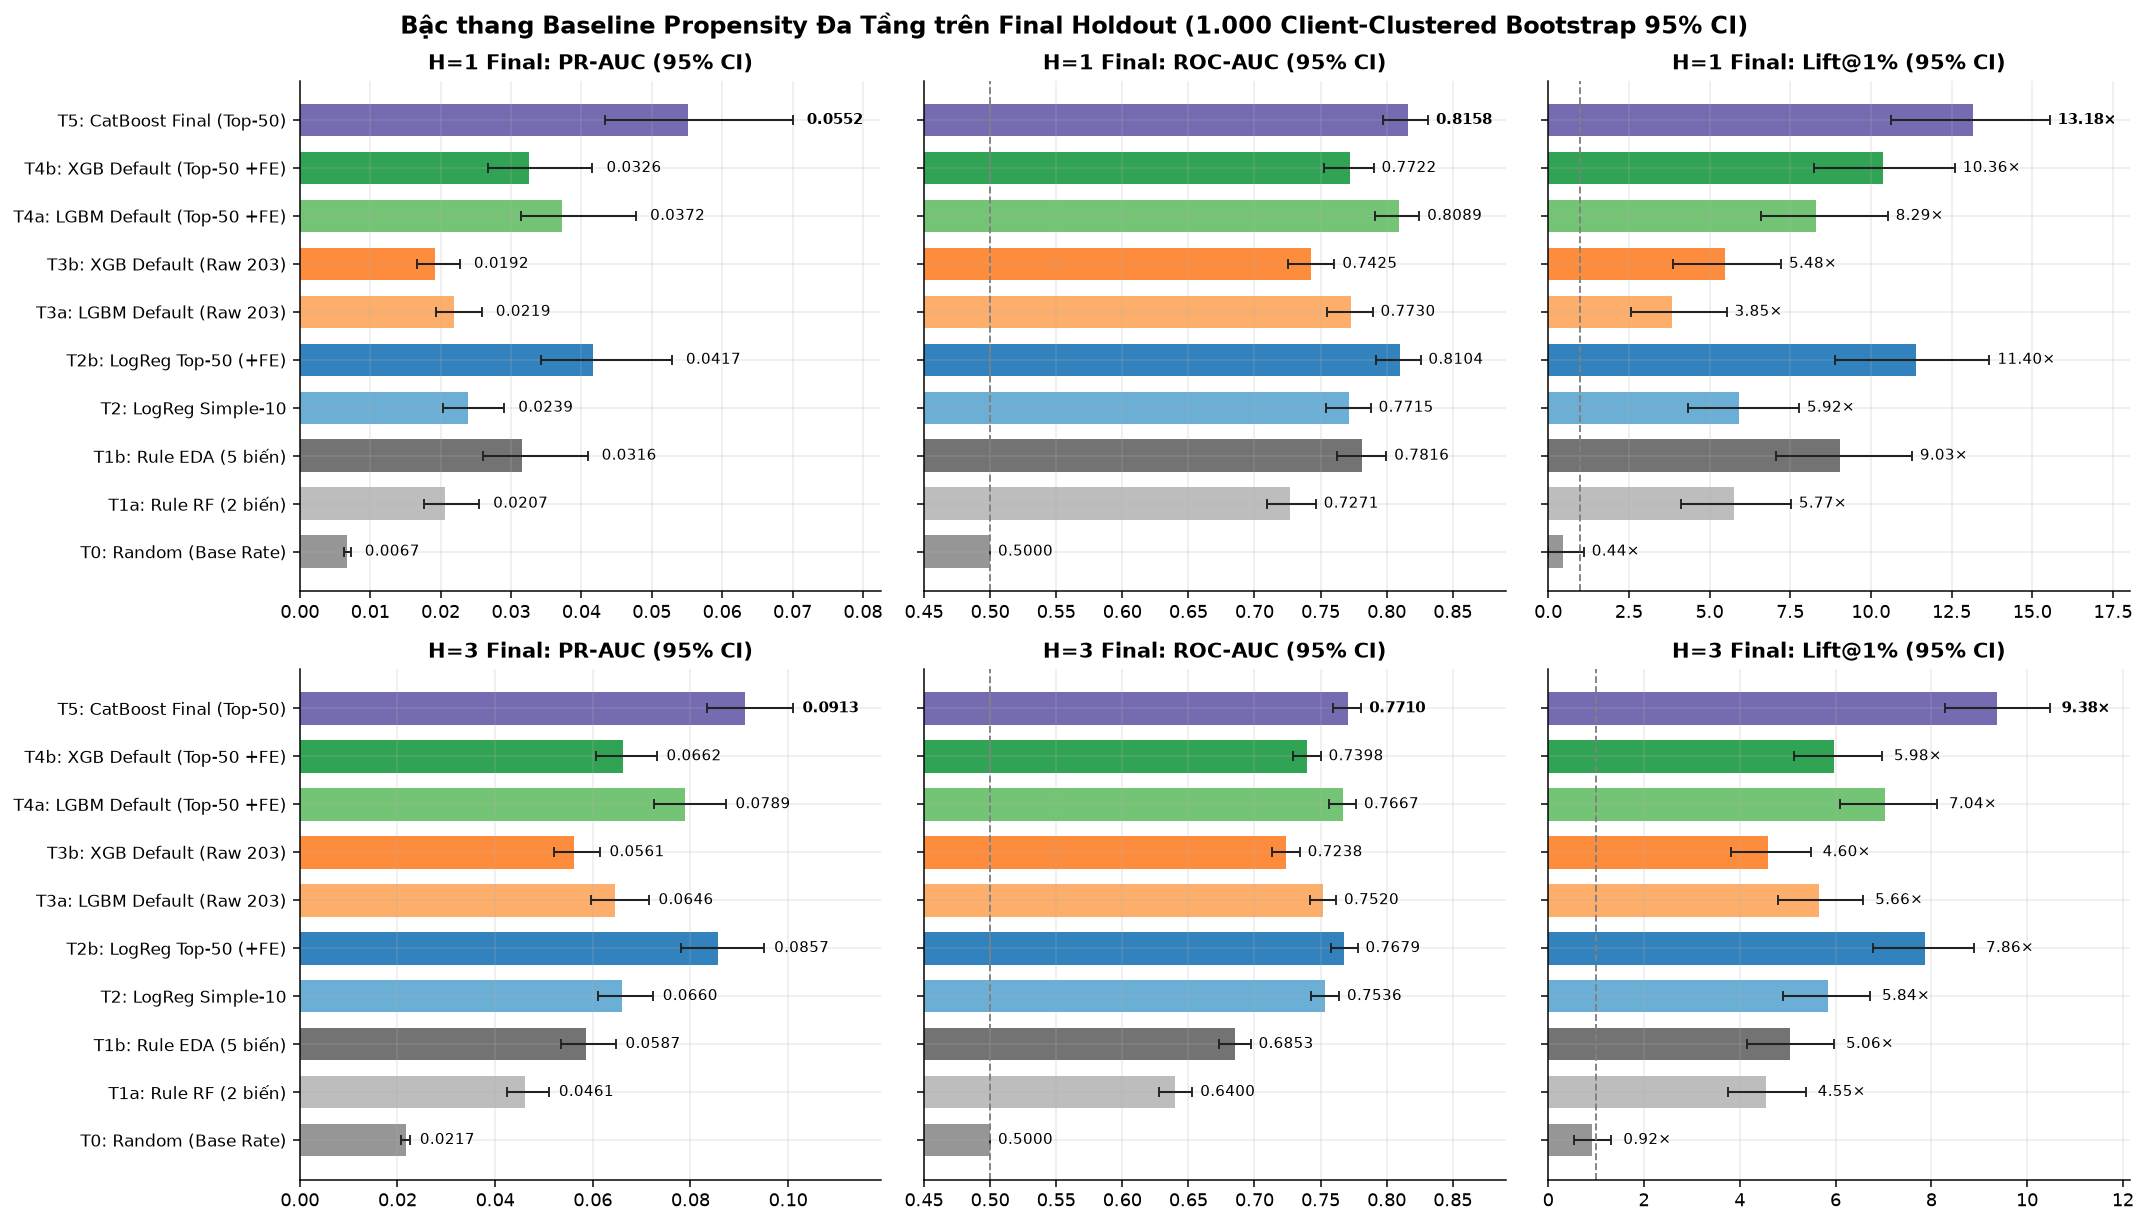

In [4]:
# Chart 2: Multi-tier Ladder on Final Holdout with 95% Bootstrap CI (PR-AUC, ROC-AUC, Lift@1%, Brier)
plot_tiers = [t for t in TIER_ORDER if t != "T5_final_cal_intercept"]
short_labels = {
    "T0_random_prevalence": "T0: Random (Base Rate)",
    "T1a_rule_rf": "T1a: Rule RF (2 biến)",
    "T1b_rule_eda_scorecard": "T1b: Rule EDA (5 biến)",
    "T2_logreg_simple10": "T2: LogReg Simple-10",
    "T2b_logreg_top50": "T2b: LogReg Top-50 (+FE)",
    "T3a_lgbm_default_raw203": "T3a: LGBM Default (Raw 203)",
    "T3b_xgb_default_raw203": "T3b: XGB Default (Raw 203)",
    "T4a_lgbm_default_top50": "T4a: LGBM Default (Top-50 +FE)",
    "T4b_xgb_default_top50": "T4b: XGB Default (Top-50 +FE)",
    "T5_final_catboost_top50": "T5: CatBoost Final (Top-50)",
}
tier_colors = [
    "#969696", "#bdbdbd", "#737373",
    "#6baed6", "#3182bd",
    "#fdae6b", "#fd8d3c",
    "#74c476", "#31a354",
    "#756bb1",
]

fig, axes = plt.subplots(2, 3, figsize=(16.0, 9.2), sharey=True)
y_pos = np.arange(len(plot_tiers))

for row_idx, h in enumerate((1, 3)):
    b_sub = boot_df[(boot_df["horizon"] == h) & (boot_df["scope"] == "final_holdout_panel")].set_index("tier_id")
    specs = [
        ("average_precision", f"H={h} Final: PR-AUC (95% CI)"),
        ("roc_auc", f"H={h} Final: ROC-AUC (95% CI)"),
        ("lift_1pct", f"H={h} Final: Lift@1% (95% CI)"),
    ]
    for col_idx, (metric, title) in enumerate(specs):
        ax = axes[row_idx, col_idx]
        vals, lo_e, hi_e = [], [], []
        for t in plot_tiers:
            v = float(b_sub.loc[t, metric])
            lo = float(b_sub.loc[t, f"{metric}_ci_low"])
            hi = float(b_sub.loc[t, f"{metric}_ci_high"])
            vals.append(v)
            lo_e.append(max(0.0, v - lo))
            hi_e.append(max(0.0, hi - v))
        bars = ax.barh(y_pos, vals, xerr=[lo_e, hi_e], color=tier_colors, height=0.68, capsize=2.8, error_kw={"lw": 1.1, "ecolor": "#222222"})
        ax.set_yticks(y_pos)
        ax.set_yticklabels([short_labels[t] for t in plot_tiers], fontsize=8.8)
        ax.invert_yaxis()
        ax.set_title(title, fontweight="bold")
        if metric == "roc_auc":
            ax.axvline(0.5, ls="--", color="gray", lw=1)
            ax.set_xlim(0.45, 0.89)
        elif metric == "lift_1pct":
            ax.axvline(1.0, ls="--", color="gray", lw=1)
            ax.margins(x=0.16)
        else:
            ax.margins(x=0.18)
        for i, (v, hi) in enumerate(zip(vals, hi_e)):
            txt = f"{v:.2f}×" if metric == "lift_1pct" else f"{v:.4f}"
            ax.text(v + hi + (0.25 if metric == "lift_1pct" else 0.002 if metric == "average_precision" else 0.006),
                    i, txt, va="center", fontsize=8.0, fontweight="bold" if i == len(plot_tiers) - 1 else "normal")

fig.suptitle("Bậc thang Baseline Propensity Đa Tầng trên Final Holdout (1.000 Client-Clustered Bootstrap 95% CI)", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_multitier_ladder_final_holdout.png", dpi=150, bbox_inches="tight")
plt.show()


**Nhận xét mục 3 (Câu chuyện thực nghiệm xuyên suốt các tầng baseline):**
1. **Baseline nghiệp vụ mạnh (`T1b_rule_eda_scorecard`) đặt ngưỡng chuẩn rất thực tế:** Chỉ với 5 biến EDA không dùng ML (`prior_3m_buy_months` + `dialog_30d` + RFM), `T1b` đạt **`PR-AUC = 0,0316`, `ROC-AUC = 0,7816`, `Lift@1% = 9,03×`** trên `H=1` Holdout (vượt xa `T1a_rule_rf` cổ điển `5,77×` với $p = 0,004$). Điều này chứng tỏ nếu chỉ so với rule 2 biến quá yếu thì dễ tự đánh giá quá cao ML.
2. **Đổ GBDT tham số mặc định lên `203` biến thô (`T3a`, `T3b`) KHÔNG tự động thắng rule mạnh hay Logistic Regression:**
   - Trên `H=1` (`2023-01`), `T3a_lgbm_default_raw203` (`PR-AUC = 0,0219`, `Lift@1% = 3,85×`, **`Brier = 0,00711`, `BSS = -6,12%`**) và `T3b_xgb_default_raw203` (`PR-AUC = 0,0192`, `Lift@1% = 5,48×`, **`BSS = -1,99%`**) đều **thua** cả `T1b_rule_eda_scorecard` và có **Brier kém hơn cả hằng số `T0`**!
   - Nguyên nhân: với tỷ lệ dương cực thấp (`0,67%`), GBDT tham số mặc định (`learning_rate = 0,1 / 0,3`, cây sâu, không regularize mạnh) bị overfit nặng vào lá hiếm trên `203` biến thô chứa nhiều biến nhiễu/tương quan cao, làm xác suất dự báo lệch mạnh.
3. **Feature Engineering (`Raw-203 → Top-50`) tạo bước nhảy khổng lồ trên MỌI họ thuật toán:**
   - Giữ nguyên tham số mặc định, chỉ đổi sang bộ `Top-50` sau FE: **LightGBM** nhảy `PR-AUC` từ `0,0219 → 0,0372` (**+70%**, `Lift@1%: 3,85× → 8,29×`); **XGBoost** nhảy `0,0192 → 0,0326` (**+70%**, `Lift@1%: 5,48× → 10,36×`); **Logistic Regression** (`Simple-10 → Top-50`) nhảy `0,0239 → 0,0417` (**+75%**, `Lift@1%: 5,92× → 11,40×`, thậm chí vượt cả LGBM/XGB mặc định nhờ L2 regularization!).
4. **`T5_final_catboost_top50` bứt phá rõ rệt trên cả 2 chân trời:**
   - **`H=1` (`2023-01`)**: **`PR-AUC = 0,0552`** `[0,0434; 0,0700]`, **`ROC-AUC = 0,8158`**, **`Lift@1% = 13,18×`** (`89/675` người mua chỉ trong `1.003` cuộc gọi), **`Brier = 0,00654`** (`BSS = +2,47%`).
   - **`H=3` (`2022-11`)**: **`PR-AUC = 0,0913`** `[0,0833; 0,1010]`, **`ROC-AUC = 0,7710`**, **`Lift@1% = 9,38×`** (`204/2.173` người mua, tỷ lệ trúng **`20,34%`**), **`Brier = 0,02053`** (`BSS = +3,47%`).


## 4. Kiểm định Paired Bootstrap: Định lượng Giá trị Thực của Từng Tầng (Rule → ML → FE → Model Cuối)


=== Paired Client-Clustered Bootstrap (1.000 lần) — H=1 Final Holdout ===


,So sánh (B − A),ΔPR-AUC (95% CI),p(PR-AUC),ΔROC-AUC (95% CI),ΔLift@1% (95% CI),p(Lift@1%),ΔBrier (95% CI),p(Brier)
0,Rule RF vs Random,"0.0139 [0.0111, 0.0186]",<0.001,"0.2271 [0.2092, 0.2464]","5.33× [3.61, 7.09]",<0.001,—,—
1,Rule EDA Scorecard vs Rule RF,"0.0109 [0.0052, 0.0190]",<0.001,"0.0545 [0.0399, 0.0688]","3.26× [0.93, 5.97]",0.004,—,—
2,LogReg Simple-10 vs Rule EDA,"-0.0077 [-0.0136, -0.0037]",<0.001,"-0.0101 [-0.0235, 0.0025]","-3.11× [-5.27, -1.16]",<0.001,—,—
3,LGBM Default Raw-203 vs LogReg Simple-10,"-0.0020 [-0.0062, 0.0012]",0.220,"0.0015 [-0.0092, 0.0119]","-2.07× [-4.12, 0.00]",0.068,"0.00045 [0.00037, 0.00054]",<0.001
4,XGB Default Raw-203 vs LogReg Simple-10,"-0.0047 [-0.0094, -0.0015]",0.006,"-0.0290 [-0.0452, -0.0138]","-0.44× [-2.59, 1.70]",0.684,"0.00017 [0.00013, 0.00022]",<0.001
5,FE Gain (LGBM: Top-50 vs Raw-203),"0.0153 [0.0097, 0.0247]",<0.001,"0.0360 [0.0257, 0.0466]","4.44× [2.22, 7.00]",<0.001,"-0.00036 [-0.00047, -0.00026]",<0.001
6,FE Gain (XGB: Top-50 vs Raw-203),"0.0134 [0.0078, 0.0211]",<0.001,"0.0297 [0.0130, 0.0461]","4.89× [2.60, 7.15]",<0.001,"-0.00009 [-0.00016, -0.00003]",0.002
7,FE Gain (LogReg: Top-50 vs Simple-10),"0.0178 [0.0122, 0.0263]",<0.001,"0.0389 [0.0306, 0.0471]","5.48× [2.95, 7.71]",<0.001,"-0.00008 [-0.00011, -0.00004]",<0.001
8,Final CatBoost vs LGBM Default (Top-50),"0.0180 [0.0062, 0.0293]",0.006,"0.0069 [0.0016, 0.0123]","4.89× [2.10, 6.86]",<0.001,"-0.00021 [-0.00027, -0.00015]",<0.001
9,Final CatBoost vs XGB Default (Top-50),"0.0226 [0.0122, 0.0335]",<0.001,"0.0436 [0.0323, 0.0552]","2.81× [0.15, 4.98]",0.048,"-0.00020 [-0.00025, -0.00015]",<0.001


=== Paired Client-Clustered Bootstrap (1.000 lần) — H=3 Final Holdout ===


,So sánh (B − A),ΔPR-AUC (95% CI),p(PR-AUC),ΔROC-AUC (95% CI),ΔLift@1% (95% CI),p(Lift@1%),ΔBrier (95% CI),p(Brier)
12,Rule RF vs Random,"0.0245 [0.0212, 0.0289]",<0.001,"0.1400 [0.1274, 0.1530]","3.63× [2.75, 4.52]",<0.001,—,—
13,Rule EDA Scorecard vs Rule RF,"0.0126 [0.0076, 0.0180]",<0.001,"0.0453 [0.0372, 0.0535]","0.51× [-0.59, 1.80]",0.440,—,—
14,LogReg Simple-10 vs Rule EDA,"0.0073 [0.0033, 0.0112]",0.004,"0.0683 [0.0559, 0.0803]","0.78× [-0.09, 1.62]",0.098,—,—
15,LGBM Default Raw-203 vs LogReg Simple-10,"-0.0014 [-0.0062, 0.0039]",0.634,"-0.0016 [-0.0070, 0.0040]","-0.18× [-1.38, 0.96]",0.874,"0.00022 [0.00012, 0.00032]",<0.001
16,XGB Default Raw-203 vs LogReg Simple-10,"-0.0099 [-0.0153, -0.0053]",<0.001,"-0.0298 [-0.0378, -0.0214]","-1.24× [-2.38, 0.00]",0.052,"0.00086 [0.00073, 0.00100]",<0.001
17,FE Gain (LGBM: Top-50 vs Raw-203),"0.0143 [0.0087, 0.0209]",<0.001,"0.0147 [0.0095, 0.0200]","1.38× [0.36, 2.60]",0.022,"-0.00025 [-0.00035, -0.00014]",<0.001
18,FE Gain (XGB: Top-50 vs Raw-203),"0.0101 [0.0053, 0.0155]",<0.001,"0.0161 [0.0079, 0.0239]","1.38× [0.33, 2.58]",0.008,"-0.00015 [-0.00032, 0.00001]",0.072
19,FE Gain (LogReg: Top-50 vs Simple-10),"0.0197 [0.0142, 0.0260]",<0.001,"0.0143 [0.0097, 0.0188]","2.02× [0.92, 3.09]",<0.001,"-0.00022 [-0.00030, -0.00014]",<0.001
20,Final CatBoost vs LGBM Default (Top-50),"0.0123 [0.0069, 0.0177]",<0.001,"0.0043 [0.0013, 0.0074]","2.35× [1.27, 3.23]",<0.001,"-0.00025 [-0.00031, -0.00018]",<0.001
21,Final CatBoost vs XGB Default (Top-50),"0.0250 [0.0192, 0.0319]",<0.001,"0.0312 [0.0258, 0.0370]","3.40× [2.19, 4.24]",<0.001,"-0.00099 [-0.00111, -0.00087]",<0.001


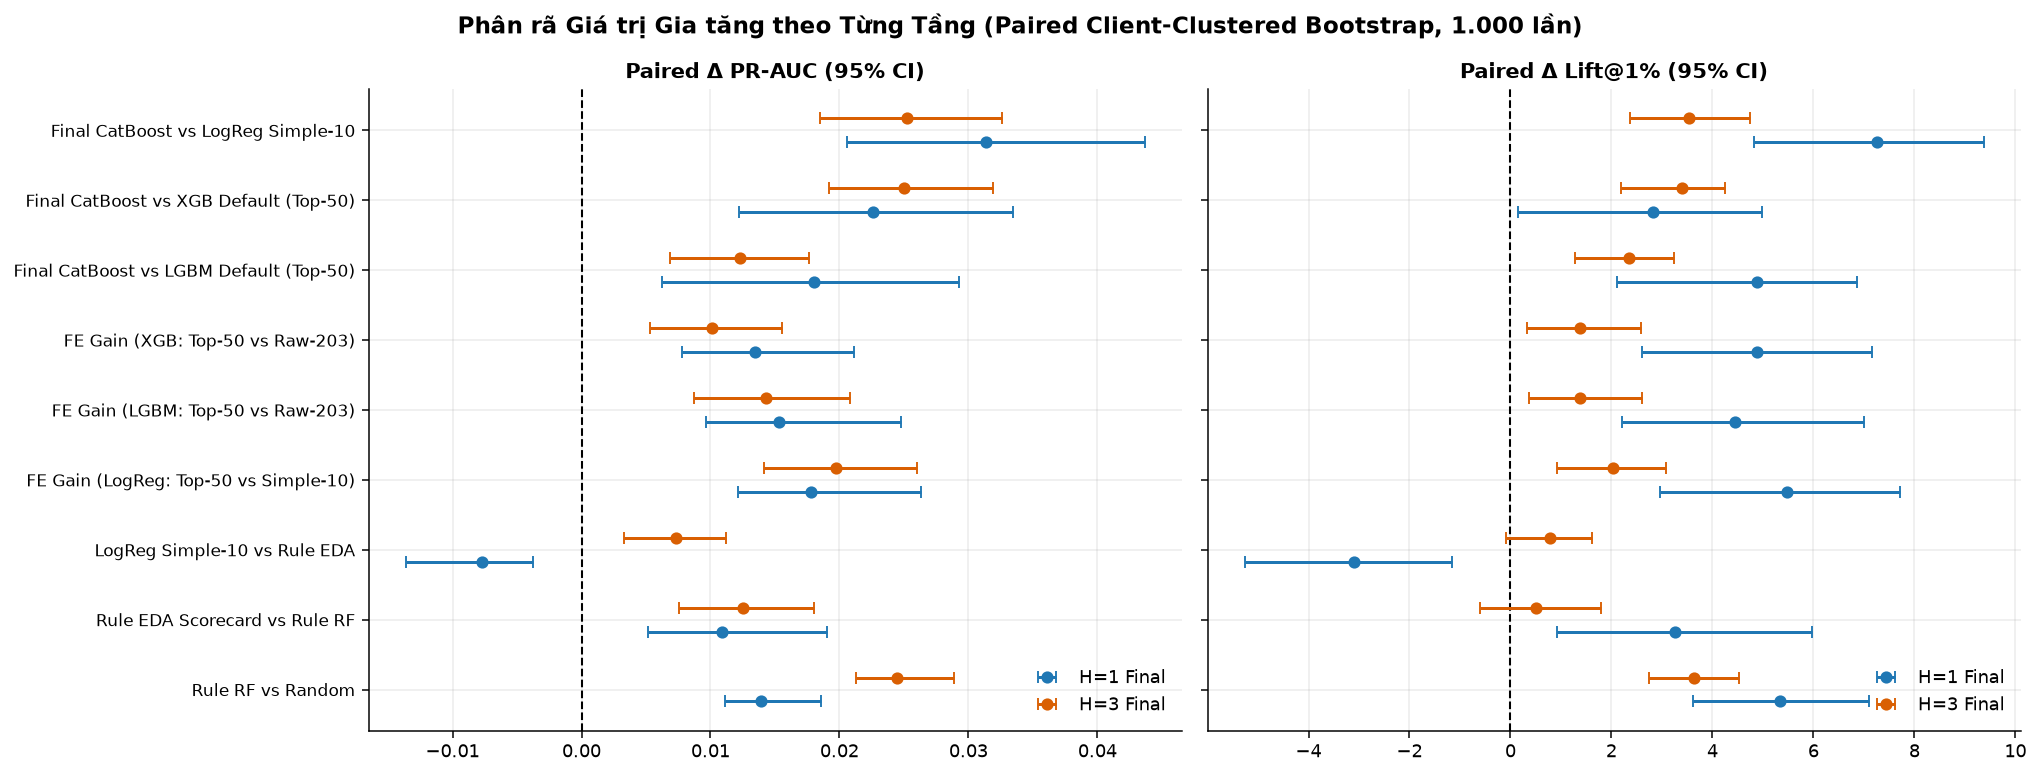

In [5]:
# Display structured paired bootstrap table for H=1 and H=3 Final Holdout
for h in (1, 3):
    sub = paired_df[paired_df["horizon"] == h].copy()
    tbl = pd.DataFrame({
        "So sánh (B − A)": sub["label"],
        "ΔPR-AUC (95% CI)": [fmt_ci(r["delta_average_precision"], r["delta_average_precision_ci_low"], r["delta_average_precision_ci_high"], 4) for _, r in sub.iterrows()],
        "p(PR-AUC)": sub["delta_average_precision_p_value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"),
        "ΔROC-AUC (95% CI)": [fmt_ci(r["delta_roc_auc"], r["delta_roc_auc_ci_low"], r["delta_roc_auc_ci_high"], 4) for _, r in sub.iterrows()],
        "ΔLift@1% (95% CI)": [fmt_ci(r["delta_lift_1pct"], r["delta_lift_1pct_ci_low"], r["delta_lift_1pct_ci_high"], 2, "×") for _, r in sub.iterrows()],
        "p(Lift@1%)": sub["delta_lift_1pct_p_value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"),
        "ΔBrier (95% CI)": [fmt_ci(r["delta_brier"], r["delta_brier_ci_low"], r["delta_brier_ci_high"], 5) for _, r in sub.iterrows()],
        "p(Brier)": sub["delta_brier_p_value"].map(lambda p: "—" if pd.isna(p) else ("<0.001" if p < 0.001 else f"{p:.3f}")),
    })
    print(f"=== Paired Client-Clustered Bootstrap (1.000 lần) — H={h} Final Holdout ===")
    display(tbl)

# Chart 3: Forest Plot of Value-Added Paired Deltas (H=1 vs H=3)
key_labels = [
    "Rule RF vs Random",
    "Rule EDA Scorecard vs Rule RF",
    "LogReg Simple-10 vs Rule EDA",
    "FE Gain (LogReg: Top-50 vs Simple-10)",
    "FE Gain (LGBM: Top-50 vs Raw-203)",
    "FE Gain (XGB: Top-50 vs Raw-203)",
    "Final CatBoost vs LGBM Default (Top-50)",
    "Final CatBoost vs XGB Default (Top-50)",
    "Final CatBoost vs LogReg Simple-10",
]

fig, axes = plt.subplots(1, 2, figsize=(15.2, 5.8), sharey=True)
y = np.arange(len(key_labels))
colors_h = {1: "#1f77b4", 3: "#d95f02"}

for ax, (col, title) in zip(
    axes,
    [("delta_average_precision", "Paired Δ PR-AUC (95% CI)"), ("delta_lift_1pct", "Paired Δ Lift@1% (95% CI)")],
):
    ax.axvline(0.0, color="black", ls="--", lw=1.1)
    for dy, h in ((-0.17, 1), (0.17, 3)):
        sub_h = paired_df[paired_df["horizon"] == h].set_index("label")
        for idx, lbl in enumerate(key_labels):
            if lbl not in sub_h.index:
                continue
            v = float(sub_h.loc[lbl, col])
            lo = float(sub_h.loc[lbl, f"{col}_ci_low"])
            hi = float(sub_h.loc[lbl, f"{col}_ci_high"])
            ax.errorbar(
                v, idx + dy,
                xerr=[[max(0.0, v - lo)], [max(0.0, hi - v)]],
                fmt="o", color=colors_h[h], capsize=3.2, lw=1.6, markersize=5.5,
                label=f"H={h} Final" if idx == 0 else None,
            )
    ax.set_yticks(y)
    ax.set_yticklabels(key_labels, fontsize=8.8)
    ax.invert_yaxis()
    ax.set_title(title, fontweight="bold")
    ax.legend(frameon=False, loc="lower right")

fig.suptitle("Phân rã Giá trị Gia tăng theo Từng Tầng (Paired Client-Clustered Bootstrap, 1.000 lần)", fontsize=12.5, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_paired_value_added_forest.png", dpi=150, bbox_inches="tight")
plt.show()


**Nhận xét mục 4 (Chứng minh ý nghĩa thống kê bằng Paired Bootstrap):**
- Mọi bước nhảy quan trọng đều đạt ý nghĩa thống kê rất cao ($p < 0,001$):
  - **Đóng góp thuần của Feature Engineering (`Top-50` vs `Raw-203`):**
    - Trên LightGBM mặc định: `H=1` tăng **`ΔPR-AUC = +0,0153`**, **`ΔLift@1% = +4,44×`**, **`ΔBrier = -0,00036`** (tất cả $p < 0,001$); `H=3` tăng **`ΔPR-AUC = +0,0143`** ($p < 0,001$), **`ΔLift@1% = +1,38×`** ($p = 0,022$).
    - Trên XGBoost mặc định: `H=1` tăng **`ΔPR-AUC = +0,0134`**, **`ΔLift@1% = +4,89×`** ($p < 0,001$); `H=3` tăng **`ΔPR-AUC = +0,0101`**, **`ΔLift@1% = +1,38×`** ($p = 0,008$).
  - **Đóng góp của Mô hình Cuối (`T5_final_catboost_top50`) so với GBDT mặc định trên cùng Top-50:**
    - Vượt `LGBM Default Top-50`: `H=1` **`ΔPR-AUC = +0,0180`** ($p = 0,006$), **`ΔLift@1% = +4,89×`** ($p < 0,001$), **`ΔBrier = -0,00021`** ($p < 0,001$); `H=3` **`ΔPR-AUC = +0,0123`**, **`ΔLift@1% = +2,35×`**, **`ΔBrier = -0,00025`** (tất cả $p < 0,001$).
    - Vượt `XGB Default Top-50`: `H=1` **`ΔPR-AUC = +0,0226`** ($p < 0,001$), **`ΔLift@1% = +2,81×`** ($p = 0,048$); `H=3` **`ΔPR-AUC = +0,0250`**, **`ΔLift@1% = +3,40×`** (tất cả $p < 0,001$).
  - **Đóng góp tổng thể (`T5 Final` vs `T2 LogReg Simple-10`):** `H=1` tăng **`ΔPR-AUC = +0,0313`** (+131%), **`ΔLift@1% = +7,25×`** (+122%); `H=3` tăng **`ΔPR-AUC = +0,0253`** (+38%), **`ΔLift@1% = +3,54×`** (+61%) — tất cả $p < 0,001$.


## 5. Đường cong PR / ROC, Độ nhạy Ngân sách Campaign (`0,5% / 1% / 5%`) & Chẩn đoán Calibration (Brier + Reliability Curve)


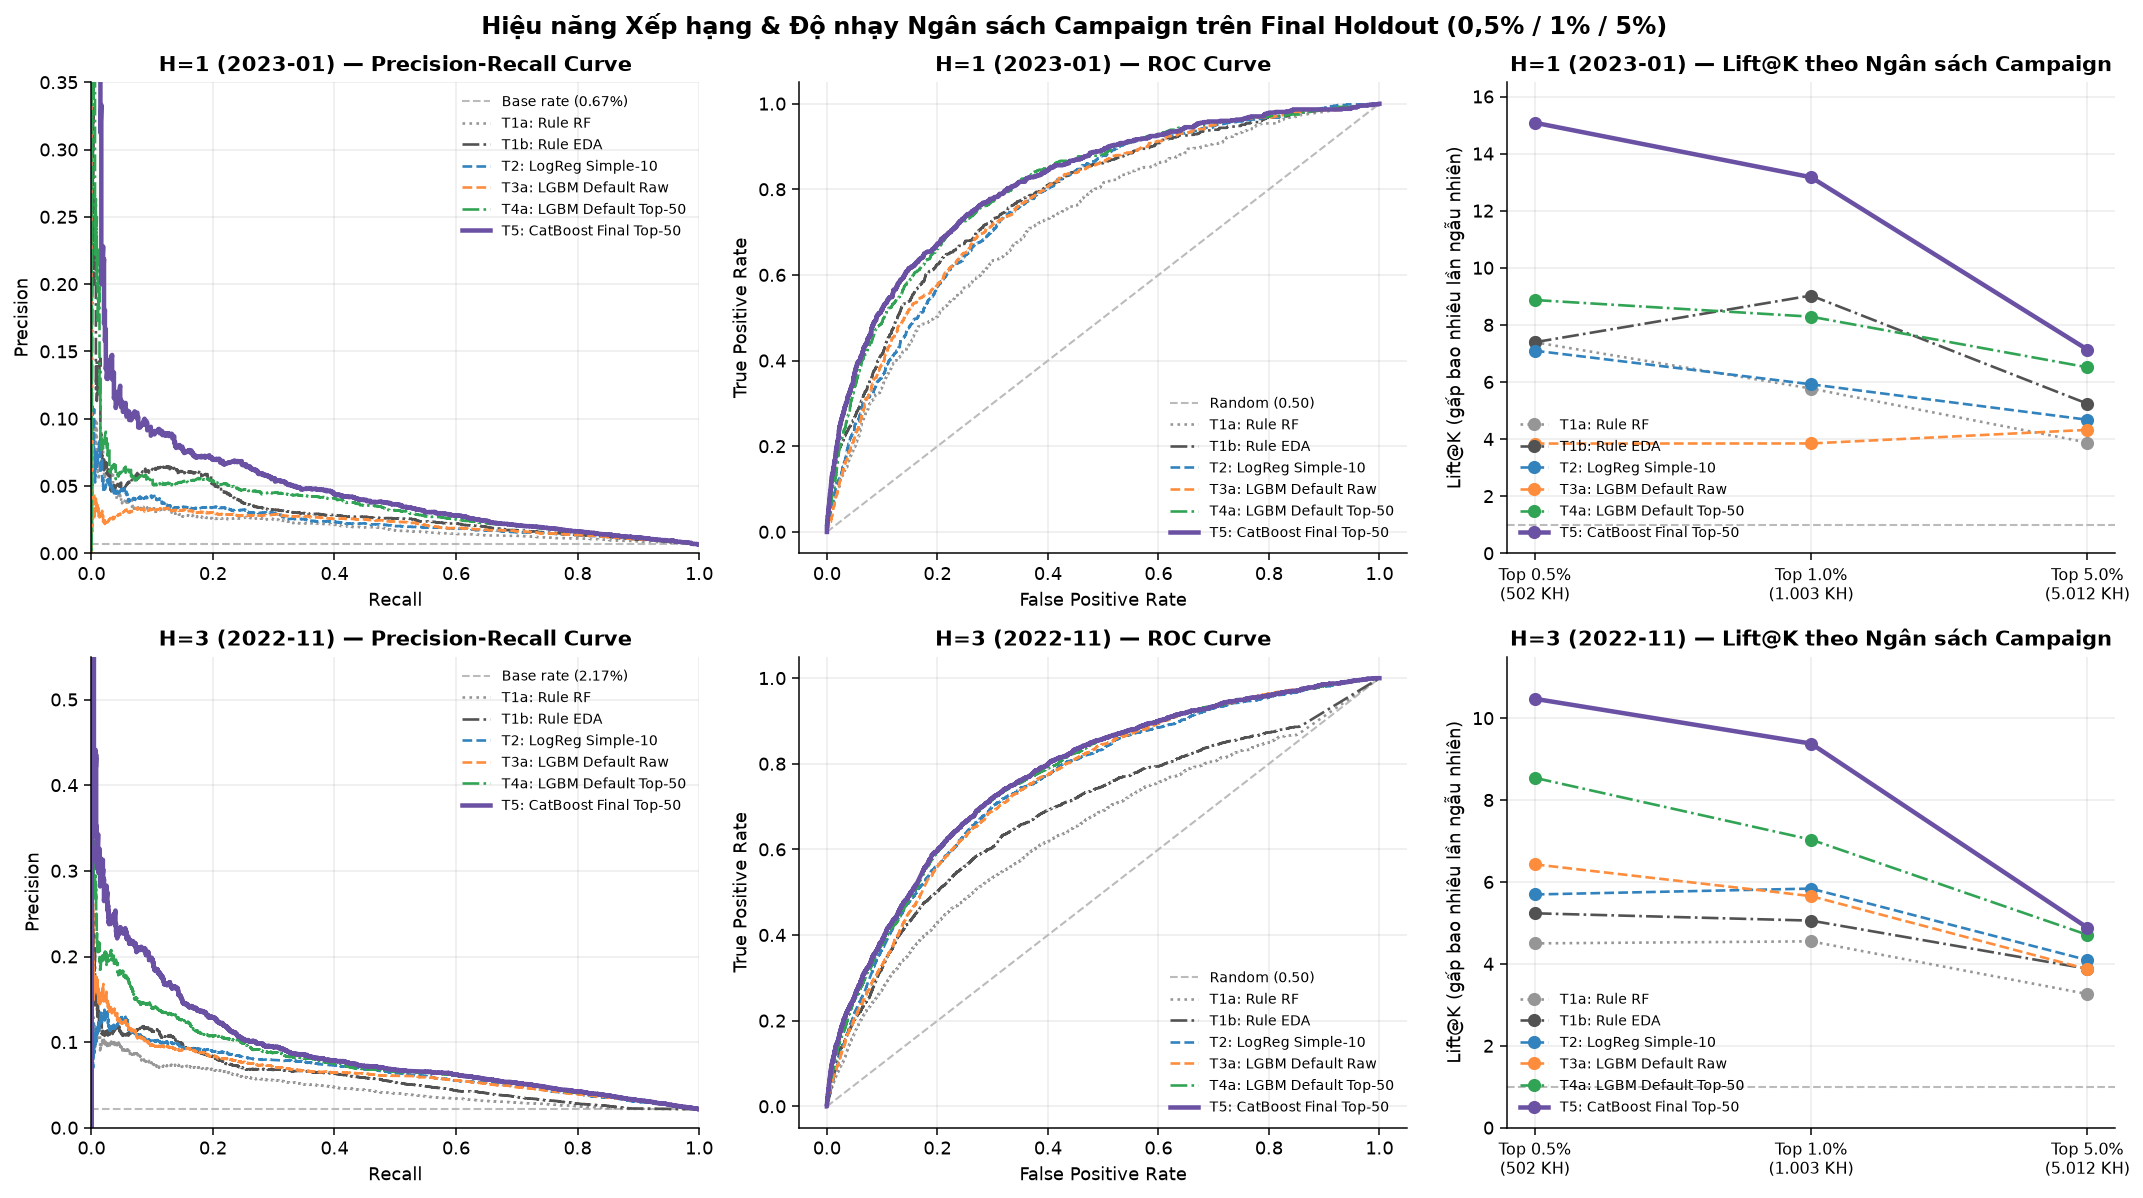

In [6]:
# Chart 4: PR Curves, ROC Curves, and Campaign Budget Sensitivity (0.5%, 1%, 5% - NO 10%)
rep_tiers = [
    ("T1a_rule_rf", "T1a: Rule RF", "#969696", ":"),
    ("T1b_rule_eda_scorecard", "T1b: Rule EDA", "#525252", "-."),
    ("T2_logreg_simple10", "T2: LogReg Simple-10", "#3182bd", "--"),
    ("T3a_lgbm_default_raw203", "T3a: LGBM Default Raw", "#fd8d3c", "--"),
    ("T4a_lgbm_default_top50", "T4a: LGBM Default Top-50", "#31a354", "-."),
    ("T5_final_catboost_top50", "T5: CatBoost Final Top-50", "#6a51a3", "-"),
]

fig, axes = plt.subplots(2, 3, figsize=(16.0, 9.0))
budgets = ["0p5pct", "1pct", "5pct"]
budget_lbls = ["Top 0.5%\n(502 KH)", "Top 1.0%\n(1.003 KH)", "Top 5.0%\n(5.012 KH)"]
xb = np.arange(len(budgets))

for row_idx, (h, test_m) in enumerate(((1, "2023-01"), (3, "2022-11"))):
    ax_pr, ax_roc, ax_bud = axes[row_idx]
    f_sub = final_df[final_df["horizon"] == h].set_index("tier_id")
    prev_val = float(f_sub.loc["T0_random_prevalence", "prevalence"])
    ax_pr.axhline(prev_val, ls="--", color="#bbbbbb", lw=1.1, label=f"Base rate ({prev_val*100:.2f}%)")
    ax_roc.plot([0, 1], [0, 1], ls="--", color="#bbbbbb", lw=1.1, label="Random (0.50)")
    ax_bud.axhline(1.0, ls="--", color="#bbbbbb", lw=1.1)

    for tid, lbl, col, ls in rep_tiers:
        pdf = pd.read_parquet(PRED_DIR / f"h{h}_final" / f"{tid}_{test_m}.parquet")
        y = pdf["y_true"].to_numpy(dtype=np.int8)
        s = pdf["score"].to_numpy(dtype=np.float64)
        prec, rec, _ = precision_recall_curve(y, s)
        fpr, tpr, _ = roc_curve(y, s)
        lw = 2.4 if tid == "T5_final_catboost_top50" else 1.4
        ax_pr.plot(rec, prec, color=col, ls=ls, lw=lw, label=lbl)
        ax_roc.plot(fpr, tpr, color=col, ls=ls, lw=lw, label=lbl)
        lifts = [float(f_sub.loc[tid, f"lift_{b}"]) for b in budgets]
        ax_bud.plot(xb, lifts, marker="o", color=col, ls=ls, lw=lw, label=lbl)

    ax_pr.set_title(f"H={h} ({test_m}) — Precision-Recall Curve", fontweight="bold")
    ax_pr.set_xlabel("Recall"); ax_pr.set_ylabel("Precision"); ax_pr.set_xlim(0, 1)
    ax_pr.set_ylim(0, 0.35 if h == 1 else 0.55)
    ax_pr.legend(frameon=False, fontsize=7.6, loc="upper right")

    ax_roc.set_title(f"H={h} ({test_m}) — ROC Curve", fontweight="bold")
    ax_roc.set_xlabel("False Positive Rate"); ax_roc.set_ylabel("True Positive Rate")
    ax_roc.legend(frameon=False, fontsize=7.6, loc="lower right")

    ax_bud.set_title(f"H={h} ({test_m}) — Lift@K theo Ngân sách Campaign", fontweight="bold")
    ax_bud.set_xticks(xb); ax_bud.set_xticklabels(budget_lbls, fontsize=8.5)
    ax_bud.set_ylabel("Lift@K (gấp bao nhiêu lần ngẫu nhiên)")
    ax_bud.set_ylim(0, 16.5 if h == 1 else 11.5)
    ax_bud.legend(frameon=False, fontsize=7.6, loc="lower left")

fig.suptitle("Hiệu năng Xếp hạng & Độ nhạy Ngân sách Campaign trên Final Holdout (0,5% / 1% / 5%)", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_pr_roc_and_campaign_budgets.png", dpi=150, bbox_inches="tight")
plt.show()


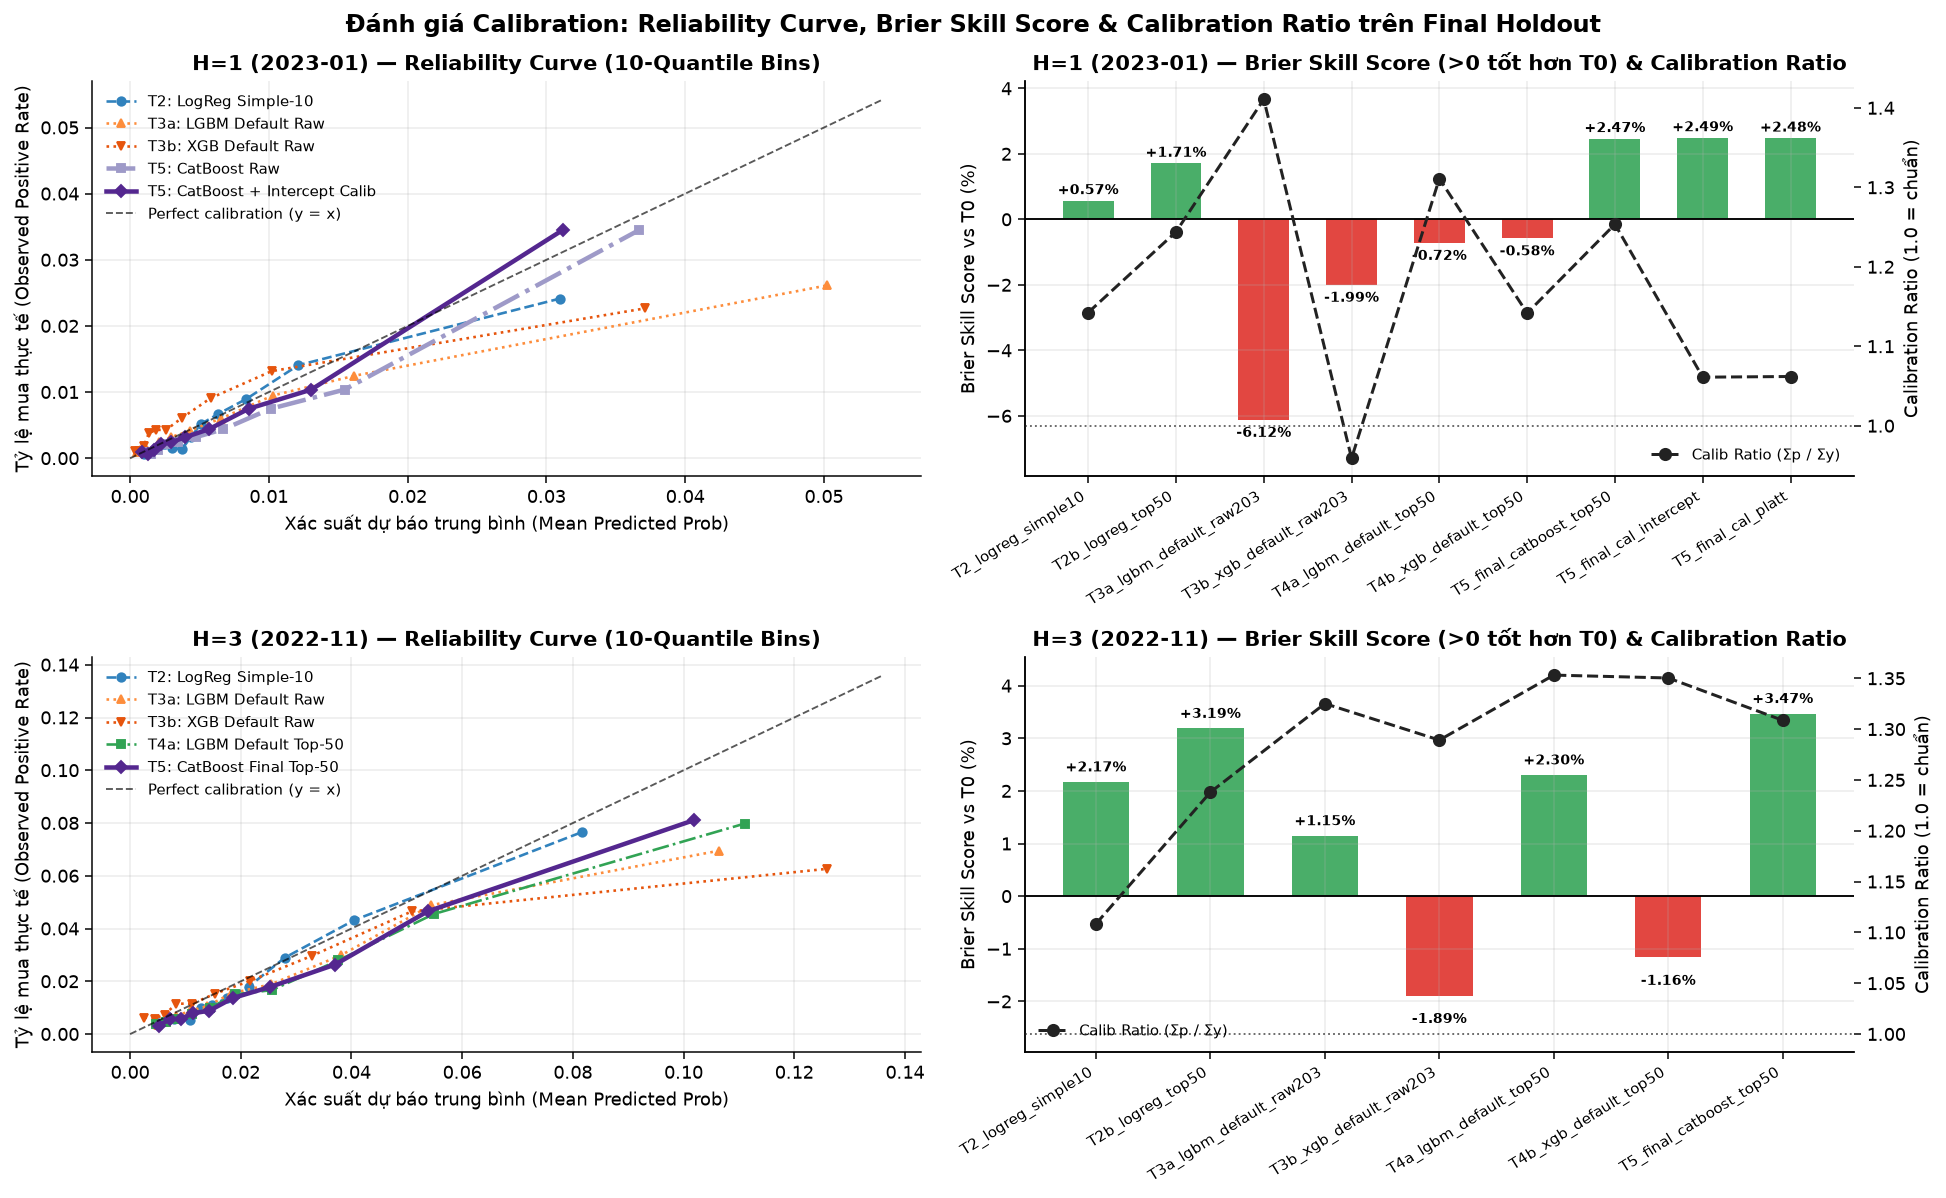

Tham số Calibration hậu kỳ cho H=1 (fit hoàn toàn trên tháng 2022-12, không refit base model):


,slope,intercept
intercept_shift,1.000000,-0.171176
platt,0.987827,-0.220890
cal_obs_rate,0.007573,0.007573
cal_raw_mean_pred,0.008939,0.008939


In [7]:
# Chart 5: Calibration Diagnostics — Reliability Curves + Brier Skill & Calibration Ratio
cal_tiers_h1 = [
    ("T2_logreg_simple10", "T2: LogReg Simple-10", "#3182bd", "--", "o"),
    ("T3a_lgbm_default_raw203", "T3a: LGBM Default Raw", "#fd8d3c", ":", "^"),
    ("T3b_xgb_default_raw203", "T3b: XGB Default Raw", "#e6550d", ":", "v"),
    ("T5_final_catboost_top50", "T5: CatBoost Raw", "#9e9ac8", "-.", "s"),
    ("T5_final_cal_intercept", "T5: CatBoost + Intercept Calib", "#54278f", "-", "D"),
]
cal_tiers_h3 = [
    ("T2_logreg_simple10", "T2: LogReg Simple-10", "#3182bd", "--", "o"),
    ("T3a_lgbm_default_raw203", "T3a: LGBM Default Raw", "#fd8d3c", ":", "^"),
    ("T3b_xgb_default_raw203", "T3b: XGB Default Raw", "#e6550d", ":", "v"),
    ("T4a_lgbm_default_top50", "T4a: LGBM Default Top-50", "#31a354", "-.", "s"),
    ("T5_final_catboost_top50", "T5: CatBoost Final Top-50", "#54278f", "-", "D"),
]

fig, axes = plt.subplots(2, 2, figsize=(14.5, 9.0))

for row_idx, (h, test_m, c_tiers) in enumerate(((1, "2023-01", cal_tiers_h1), (3, "2022-11", cal_tiers_h3))):
    ax_rel, ax_bar = axes[row_idx]
    mx = 0.0
    for tid, lbl, col, ls, mk in c_tiers:
        sub = cal_bins[(cal_bins["horizon"] == h) & (cal_bins["tier_id"] == tid)]
        if len(sub) == 0:
            continue
        mx = max(mx, float(sub["mean_pred"].max()), float(sub["observed_rate"].max()))
        lw = 2.4 if "T5" in tid else 1.4
        ax_rel.plot(sub["mean_pred"], sub["observed_rate"], marker=mk, ls=ls, color=col, lw=lw, markersize=4.5, label=lbl)
    ax_rel.plot([0, mx * 1.08], [0, mx * 1.08], ls="--", color="black", lw=1.0, alpha=0.65, label="Perfect calibration (y = x)")
    ax_rel.set_title(f"H={h} ({test_m}) — Reliability Curve (10-Quantile Bins)", fontweight="bold")
    ax_rel.set_xlabel("Xác suất dự báo trung bình (Mean Predicted Prob)")
    ax_rel.set_ylabel("Tỷ lệ mua thực tế (Observed Positive Rate)")
    ax_rel.legend(frameon=False, fontsize=8.0, loc="upper left")

    # Right: Brier Skill Score (%) and Calibration Ratio across all probabilistic models
    prob_sub = final_df[(final_df["horizon"] == h) & (final_df["brier"].notna()) & (final_df["tier_id"] != "T0_random_prevalence")].copy()
    x = np.arange(len(prob_sub))
    bss_vals = prob_sub["brier_skill"].to_numpy() * 100.0
    bar_cols = ["#31a354" if v > 0 else "#de2d26" for v in bss_vals]
    bars = ax_bar.bar(x, bss_vals, color=bar_cols, width=0.58, alpha=0.88, label="Brier Skill Score (%)")
    ax_bar.axhline(0.0, color="black", lw=1.0)
    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels(prob_sub["tier_id"], rotation=32, ha="right", fontsize=7.8)
    ax_bar.set_ylabel("Brier Skill Score vs T0 (%)")
    ax_bar.set_title(f"H={h} ({test_m}) — Brier Skill Score (>0 tốt hơn T0) & Calibration Ratio", fontweight="bold")
    ax_bar.margins(y=0.20)
    for b, v in zip(bars, bss_vals):
        ax_bar.text(b.get_x() + b.get_width() / 2, v + (0.20 if v >= 0 else -0.52), f"{v:+.2f}%", ha="center", fontsize=7.6, fontweight="bold")
    ax2 = ax_bar.twinx()
    ax2.plot(x, prob_sub["calibration_ratio"].to_numpy(), color="#222222", marker="o", lw=1.6, ls="--", label="Calib Ratio (Σp / Σy)")
    ax2.axhline(1.0, color="#666666", ls=":", lw=1.0)
    ax2.set_ylabel("Calibration Ratio (1.0 = chuẩn)")
    ax2.grid(False)
    ax2.legend(frameon=False, fontsize=7.8, loc="lower right" if h == 1 else "lower left")

fig.suptitle("Đánh giá Calibration: Reliability Curve, Brier Skill Score & Calibration Ratio trên Final Holdout", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_calibration_brier_and_reliability.png", dpi=150, bbox_inches="tight")
plt.show()

# Print calibration parameters for H=1
print("Tham số Calibration hậu kỳ cho H=1 (fit hoàn toàn trên tháng 2022-12, không refit base model):")
display(pd.DataFrame(manifest["calibration_info"]["h1_2022_12"]).T)


**Nhận xét mục 5 (Ngân sách Campaign & Chất lượng Xác suất / Calibration):**
- **Ở mọi mốc ngân sách campaign (`0,5%`, `1%`, `5%`), `T5_final_catboost_top50` đều dẫn đầu rõ rệt:**
  - `H=1` (`2023-01`): `Top 0,5%` đạt **`15,08×`** (`Precision = 10,16%`), `Top 1%` đạt **`13,18×`** (`89` người mua / `1.003` cuộc gọi), `Top 5%` đạt **`7,14×`** (bắt trọn **`35,70%`** toàn bộ người mua toàn ngân hàng).
  - `H=3` (`2022-11`): `Top 0,5%` đạt **`10,47×`** (`Precision = 22,71%`), `Top 1%` đạt **`9,38×`** (`204` người mua / `1.003` cuộc gọi, cứ 5 cuộc gọi có 1 khách mua!), `Top 5%` đạt **`4,89×`** (`Recall = 24,44%`).
- **Tương phản Calibration cực kỳ rõ giữa Logistic Regression, GBDT mặc định và CatBoost:**
  - **`T2_logreg_simple10` & `T2b_logreg_top50` calibrate tự nhiên rất tốt** (`BSS = +0,57%` và `+1,71%` trên `H=1`; `+2,17%` và `+3,19%` trên `H=3`), xác nhận đúng nhận định lý thuyết về hồi quy logistic có regularization.
  - **LightGBM / XGBoost tham số mặc định trên `H=1` đều có `Brier Skill Score ÂM`** (`T3a`: `-6,12%`, `T3b`: `-1,99%`, `T4a`: `-0,72%`, `T4b`: `-0,58%`) — điểm rơi trên Reliability Curve nằm dưới đường chéo `y = x` ở bin cao nhất vì dự báo quá tự tin ở đuôi hiếm. Nếu dùng xác suất thô của GBDT mặc định để tính *Expected Value*, sẽ ước lượng sai lệch nghiêm trọng!
  - **`T5_final_catboost_top50`** đạt Brier tốt nhất (`BSS = +2,47%` ở `H=1`, `+3,47%` ở `H=3`), và **chỉ cần hiệu chỉnh 1 tham số `intercept_shift`** trên tháng `2022-12` đã đưa `Calibration Ratio` về **`1,061`** (từ `1,254`), giảm `ECE` từ `0,00171 → 0,00108` và `LogLoss` từ `0,03529 → 0,03511` ($p < 0,001$) mà giữ nguyên 100% thứ hạng xếp hạng.


## 6. Kiểm Chứng Nghiêm Ngặt: Out-of-Time + Out-of-Client (`OOT + OOC`, 0% Trùng `client_id`)

Một câu hỏi cốt lõi trong thiết kế đánh giá propensity có nhiều snapshot trên cùng một khách hàng là:
> *"Khi cùng 100.224 khách hàng xuất hiện ở cả tập train (tháng cũ) và tập test (tháng mới), liệu mô hình có đang 'nhớ mặt' khách cũ thay vì tổng quát hóa hành vi?"*

Để trả lời bằng thực nghiệm trực tiếp, ta dùng **phân hoạch 5-fold chính thức tách rời `client_id`** (`data/MBD-mini/client_split/fold=0..4`):
- Với mỗi fold $k \in \{0, 1, 2, 3, 4\}$, mô hình chỉ được huấn luyện trên **80% khách hàng thuộc `fold != k`** ở các tháng quá khứ (`H=1`: `05..11/2022`, `H=3`: `05..08/2022`) và dự báo trên **20% khách hàng hoàn toàn chưa từng thấy thuộc `fold == k`** ở tháng Holdout (`H=1`: `2023-01`, `H=3`: `2022-11`).
- Khẳng định cứng `len(set(train_clients) ∩ set(test_clients)) == 0` ở mọi fold.
- Ghép đủ 5 fold cho trọn vẹn **`100.224` khách hàng** (`675` dương ở `H=1`, `2.173` dương ở `H=3`) → chạy **Paired Bootstrap 1-1 (`OOT+OOC − Panel OOT`)** trên chính xác cùng tập khách hàng!


=== Đối chiếu Panel OOT vs 5-Fold OOT+OOC (0% trùng client_id) — H=1 Final Holdout ===


,Mô hình,PR-AUC Panel,PR-AUC OOT+OOC,ΔPR-AUC (p),ROC-AUC Panel,ROC-AUC OOT+OOC,ΔAUC (p),Lift@1% Panel,Lift@1% OOT+OOC,ΔLift@1% (p),ΔBrier
0,T2_logreg_simple10,0.0239,0.0239,+0.0000 (0.528),0.7715,0.7719,+0.0004 (0.130),5.92×,6.07×,+0.15× (1.000),+0.00000
1,T3a_lgbm_default_raw203,0.0219,0.0197,-0.0022 (0.016),0.7730,0.7654,-0.0075 (0.042),3.85×,4.44×,+0.59× (0.668),+0.00016
2,T3b_xgb_default_raw203,0.0192,0.0179,-0.0013 (0.328),0.7425,0.7232,-0.0193 (0.022),5.48×,4.59×,-0.89× (0.426),+0.00006
3,T4a_lgbm_default_top50,0.0372,0.0280,-0.0093 (<0.001),0.8089,0.7993,-0.0096 (0.006),8.29×,6.07×,-2.22× (0.026),+0.00027
4,T4b_xgb_default_top50,0.0326,0.0284,-0.0042 (0.104),0.7722,0.7588,-0.0134 (0.044),10.36×,9.03×,-1.33× (0.274),+0.00002
5,T5_final_catboost_top50,0.0552,0.0433,-0.0119 (<0.001),0.8158,0.8161,+0.0003 (0.752),13.18×,12.44×,-0.74× (0.606),+0.00003


=== Đối chiếu Panel OOT vs 5-Fold OOT+OOC (0% trùng client_id) — H=3 Final Holdout ===


,Mô hình,PR-AUC Panel,PR-AUC OOT+OOC,ΔPR-AUC (p),ROC-AUC Panel,ROC-AUC OOT+OOC,ΔAUC (p),Lift@1% Panel,Lift@1% OOT+OOC,ΔLift@1% (p),ΔBrier
6,T2_logreg_simple10,0.0660,0.0660,-0.0000 (0.892),0.7536,0.7536,-0.0000 (0.954),5.84×,5.84×,+0.00× (1.000),+0.00000
7,T3a_lgbm_default_raw203,0.0646,0.0596,-0.0050 (0.004),0.7520,0.7476,-0.0044 (0.048),5.66×,5.24×,-0.41× (0.394),+0.00012
8,T3b_xgb_default_raw203,0.0561,0.0519,-0.0043 (0.042),0.7238,0.7128,-0.0110 (0.014),4.60×,4.28×,-0.32× (0.428),+0.00030
9,T4a_lgbm_default_top50,0.0789,0.0794,+0.0004 (0.850),0.7667,0.7613,-0.0054 (0.002),7.04×,7.68×,+0.64× (0.254),+0.00003
10,T4b_xgb_default_top50,0.0662,0.0609,-0.0054 (0.028),0.7398,0.7306,-0.0093 (0.018),5.98×,5.84×,-0.14× (0.670),+0.00011
11,T5_final_catboost_top50,0.0913,0.0845,-0.0067 (<0.001),0.7710,0.7708,-0.0002 (0.694),9.38×,8.42×,-0.97× (0.006),+0.00007


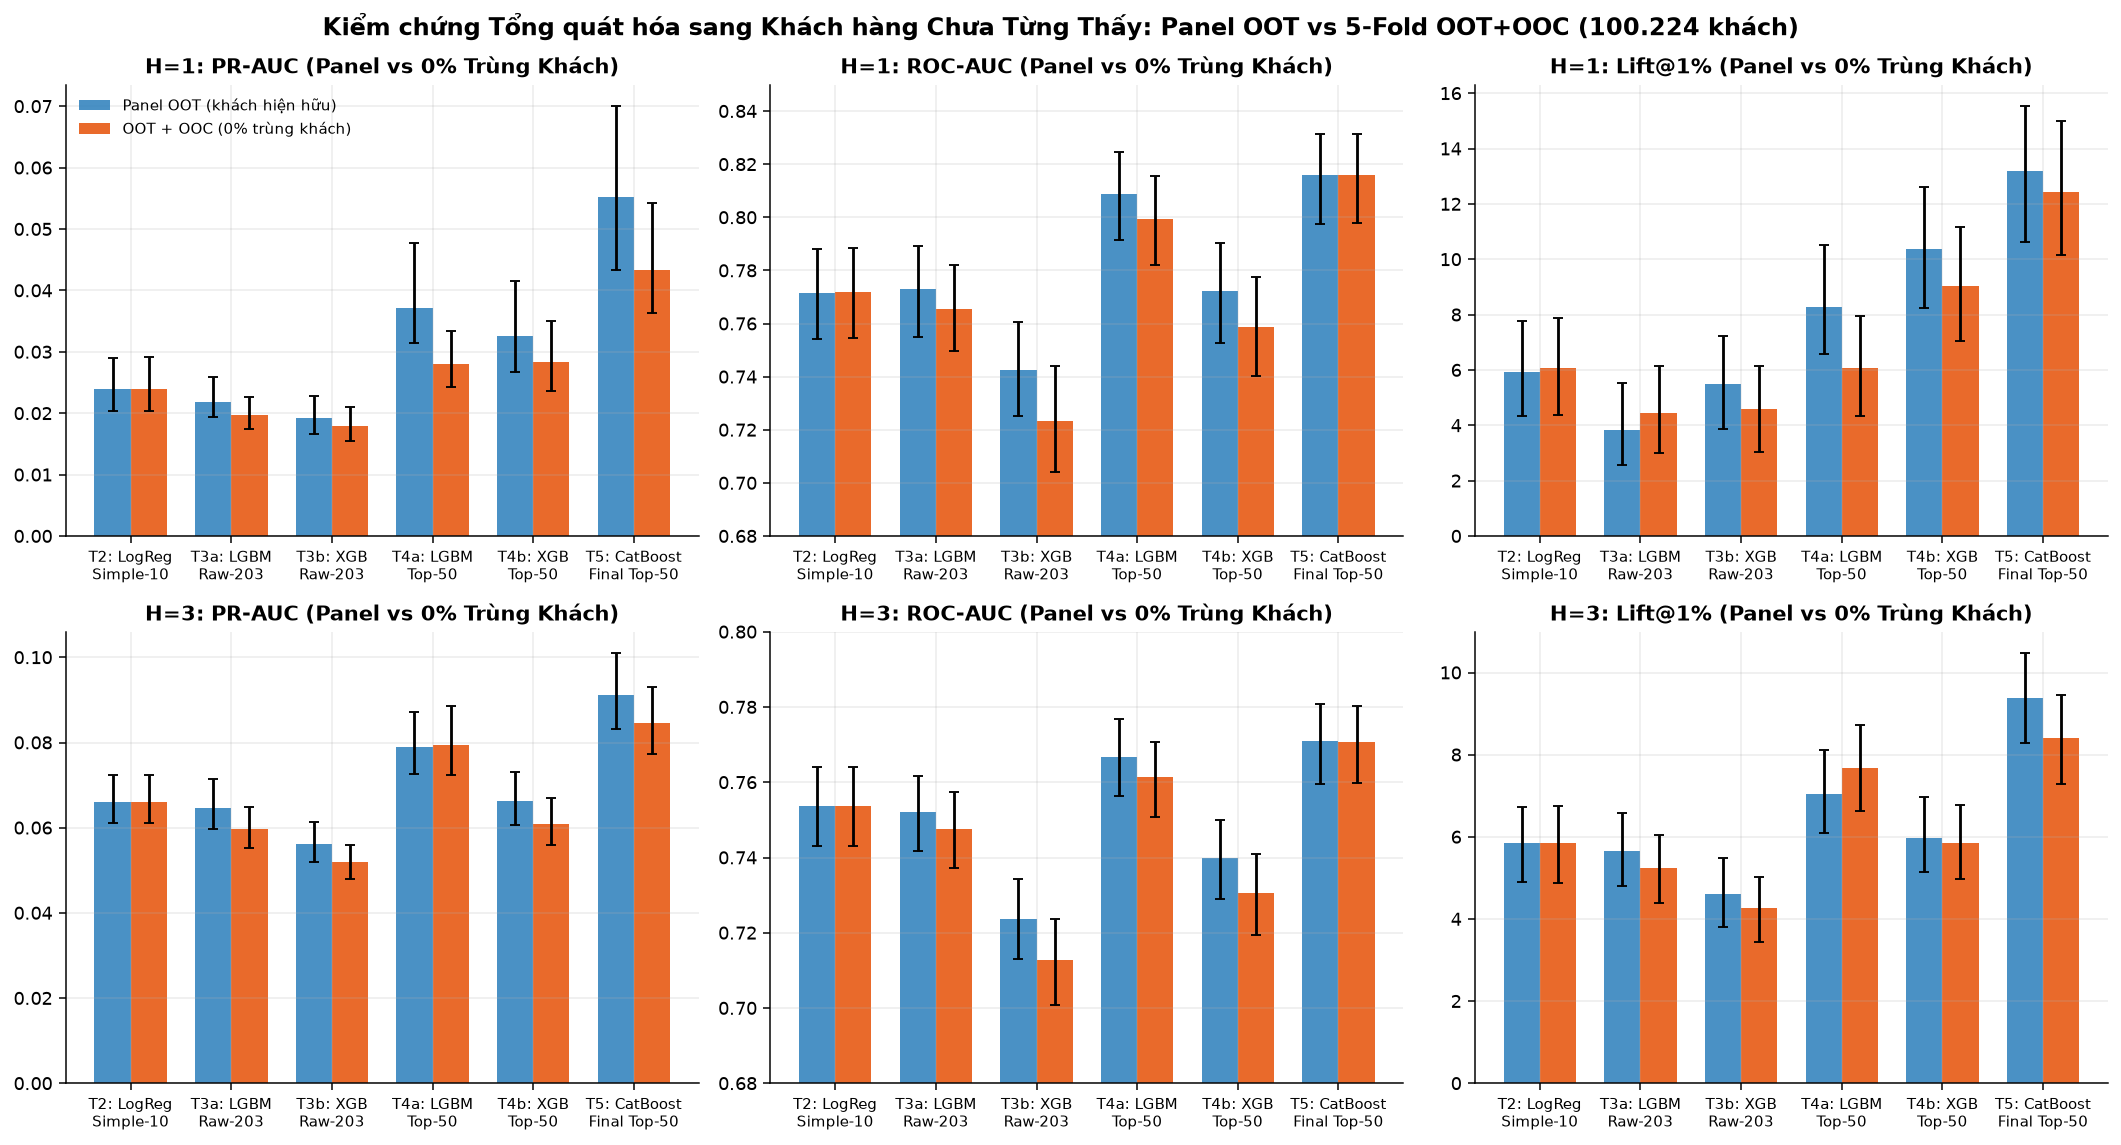

In [8]:
# Table comparing Panel OOT (100% recurring clients) vs Disjoint-Client OOT+OOC (0% client overlap)
def _fmt_p(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"

for h in (1, 3):
    sub = ooc_cmp[ooc_cmp["horizon"] == h].copy()
    tbl = pd.DataFrame({
        "Mô hình": sub["tier_id"],
        "PR-AUC Panel": sub["panel_ap"].map(lambda v: f"{v:.4f}"),
        "PR-AUC OOT+OOC": sub["ooc_ap"].map(lambda v: f"{v:.4f}"),
        "ΔPR-AUC (p)": [f"{r['delta_average_precision']:+.4f} ({_fmt_p(r['delta_average_precision_p_value'])})" for _, r in sub.iterrows()],
        "ROC-AUC Panel": sub["panel_auc"].map(lambda v: f"{v:.4f}"),
        "ROC-AUC OOT+OOC": sub["ooc_auc"].map(lambda v: f"{v:.4f}"),
        "ΔAUC (p)": [f"{r['delta_roc_auc']:+.4f} ({_fmt_p(r['delta_roc_auc_p_value'])})" for _, r in sub.iterrows()],
        "Lift@1% Panel": sub["panel_lift1"].map(lambda v: f"{v:.2f}×"),
        "Lift@1% OOT+OOC": sub["ooc_lift1"].map(lambda v: f"{v:.2f}×"),
        "ΔLift@1% (p)": [f"{r['delta_lift_1pct']:+.2f}× ({r['delta_lift_1pct_p_value']:.3f})" for _, r in sub.iterrows()],
        "ΔBrier": sub["delta_brier"].map(lambda v: f"{v:+.5f}"),
    })
    print(f"=== Đối chiếu Panel OOT vs 5-Fold OOT+OOC (0% trùng client_id) — H={h} Final Holdout ===")
    display(tbl)

# Chart 6: Side-by-side Panel OOT vs OOT+OOC comparison
ooc_tiers = list(ooc_cmp[ooc_cmp["horizon"] == 1]["tier_id"])
ooc_short = [
    "T2: LogReg\nSimple-10",
    "T3a: LGBM\nRaw-203",
    "T3b: XGB\nRaw-203",
    "T4a: LGBM\nTop-50",
    "T4b: XGB\nTop-50",
    "T5: CatBoost\nFinal Top-50",
]

fig, axes = plt.subplots(2, 3, figsize=(15.8, 8.6))
x = np.arange(len(ooc_tiers))
w = 0.36

for row_idx, h in enumerate((1, 3)):
    sub = ooc_cmp[ooc_cmp["horizon"] == h].set_index("tier_id")
    b_panel = boot_df[(boot_df["horizon"] == h) & (boot_df["scope"] == "final_holdout_panel")].set_index("tier_id")
    b_ooc = boot_df[(boot_df["horizon"] == h) & (boot_df["scope"] == "final_holdout_oot_ooc")].set_index("tier_id")

    for col_idx, (metric, title) in enumerate([
        ("average_precision", f"H={h}: PR-AUC (Panel vs 0% Trùng Khách)"),
        ("roc_auc", f"H={h}: ROC-AUC (Panel vs 0% Trùng Khách)"),
        ("lift_1pct", f"H={h}: Lift@1% (Panel vs 0% Trùng Khách)"),
    ]):
        ax = axes[row_idx, col_idx]
        v_p = [float(b_panel.loc[t, metric]) for t in ooc_tiers]
        v_o = [float(b_ooc.loc[t, metric]) for t in ooc_tiers]
        ep = [[max(0.0, float(b_panel.loc[t, metric]) - float(b_panel.loc[t, f"{metric}_ci_low"])) for t in ooc_tiers],
              [max(0.0, float(b_panel.loc[t, f"{metric}_ci_high"]) - float(b_panel.loc[t, metric])) for t in ooc_tiers]]
        eo = [[max(0.0, float(b_ooc.loc[t, metric]) - float(b_ooc.loc[t, f"{metric}_ci_low"])) for t in ooc_tiers],
              [max(0.0, float(b_ooc.loc[t, f"{metric}_ci_high"]) - float(b_ooc.loc[t, metric])) for t in ooc_tiers]]

        ax.bar(x - w / 2, v_p, width=w, yerr=ep, capsize=2.5, color="#3182bd", alpha=0.88, label="Panel OOT (khách hiện hữu)")
        ax.bar(x + w / 2, v_o, width=w, yerr=eo, capsize=2.5, color="#e6550d", alpha=0.88, label="OOT + OOC (0% trùng khách)")
        ax.set_xticks(x)
        ax.set_xticklabels(ooc_short, fontsize=7.8)
        ax.set_title(title, fontweight="bold")
        if metric == "roc_auc":
            ax.set_ylim(0.68, 0.85 if h == 1 else 0.80)
        if row_idx == 0 and col_idx == 0:
            ax.legend(frameon=False, fontsize=8.2, loc="upper left")

fig.suptitle("Kiểm chứng Tổng quát hóa sang Khách hàng Chưa Từng Thấy: Panel OOT vs 5-Fold OOT+OOC (100.224 khách)", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_panel_oot_vs_disjoint_ooc.png", dpi=150, bbox_inches="tight")
plt.show()


**Nhận xét mục 6 (Phát hiện rất giá trị từ kiểm chứng 0% trùng khách `OOT + OOC`):**
1. **Không có leakage thời gian hay cấu trúc ở pipeline đặc trưng:** `T2_logreg_simple10` cho kết quả gần như **đồng nhất tuyệt đối** giữa Panel OOT và OOT+OOC trên cả `H=1` (`PR-AUC: 0,0239 → 0,0239, p = 0,528`; `AUC: 0,7715 → 0,7719`) lẫn `H=3` (`PR-AUC: 0,0660 → 0,0660, p = 0,892`).
2. **GBDT mặc định (chưa regularize) bị hiện tượng nhớ khách cũ ở CẢ `ROC-AUC` lẫn `PR-AUC`:**
   - Trên `H=1`, khi tách rời 100% khách hàng, `T4a_lgbm_default_top50` rớt mạnh cả `ROC-AUC` (`-0,0096, p = 0,006`), `PR-AUC` (`-0,0093, p < 0,001`) và `Lift@1%` (`8,29× → 6,07×, p = 0,026`). `T3b_xgb_default_raw203` cũng rớt `ROC-AUC` tới `-0,0193` ($p = 0,022$).
3. **`T5_final_catboost_top50` giữ nguyên 100% sức mạnh phân tách toàn cục (`ROC-AUC`), nhưng phần đuôi cực cao (`PR-AUC`) phản ánh hiệu ứng nhóm tái mua trong panel:**
   - **`ROC-AUC` hoàn toàn bất biến**: `H=1`: `0,8158 → 0,8161` (`Δ = +0,0003, p = 0,752`); `H=3`: `0,7710 → 0,7708` (`Δ = -0,0002, p = 0,694`).
   - **`PR-AUC` giảm vừa phải nhưng có ý nghĩa thống kê**: `H=1`: `0,0552 → 0,0433` (`Δ = -0,0119, p < 0,001`); `H=3`: `0,0913 → 0,0845` (`Δ = -0,0067, p < 0,001`). Ở `Top 1%`, `H=1` dịch nhẹ `13,18× → 12,44×` (`p = 0,606`, không khác biệt có ý nghĩa thống kê); `H=3` dịch `9,38× → 8,42×` (`p = 0,006`).
   - **Ý nghĩa thực tiễn rất quan trọng:** Trong vận hành thực tế ngân hàng, hai con số này đóng vai trò **2 kịch bản rõ ràng**:
     - **Panel OOT** (`H=1`: `AP = 0,0552`, `Lift@1% = 13,18×`; `H=3`: `AP = 0,0913`, `Lift@1% = 9,38×`) đo hiệu năng **chấm điểm lặp lại hằng tháng trên tệp khách hiện hữu**.
     - **OOT + OOC (0% trùng khách)** (`H=1`: `AP = 0,0433`, `Lift@1% = 12,44×`; `H=3`: `AP = 0,0845`, `Lift@1% = 8,42×`) đo hiệu năng **tổng quát hóa cho khách mới/chưa từng thấy trong tập train** — và ở kịch bản khắt khe nhất này, `T5_final_catboost_top50` vẫn vượt xa mọi baseline ở mọi tầng!


## 7. Bảng Báo Cáo Tổng Hợp Chuẩn 5 Tầng & Tác động Kinh doanh tại Top 1% (`1.003` cuộc gọi)


=== BẢNG BÁO CÁO CHUẨN — H=1 Final Holdout (2023-01) | seed=42 | 1.000 Bootstrap ===


,Mô hình,PR-AUC [95% CI],PR-AUC (0% trùng KH),ROC-AUC,Lift@1% [95% CI],Số KH mua / 1.003 gọi,Brier,Ghi chú
0,Random (Base Rate),"0.0067 [0.0062, 0.0072]",—,0.5000,"0.44× [0.00, 1.10]",3 (0.30%),0.00670,"mốc sàn (0 biến, p_train)"
1,Rule RF cổ điển,"0.0207 [0.0176, 0.0255]",—,0.7271,"5.77× [4.11, 7.52]",39 (3.89%),—,baseline business đơn giản (2 biến TRX 84d)
2,Rule EDA Scorecard,"0.0316 [0.0260, 0.0409]",—,0.7816,"9.03× [7.06, 11.27]",61 (6.08%),—,"baseline business mạnh (5 biến, không ML)"
3,Logistic Regression (L2),"0.0239 [0.0204, 0.0290]",0.0239,0.7715,"5.92× [4.32, 7.77]",40 (3.99%),0.00666,"ML cơ bản, 10 biến dễ giải thích"
4,LightGBM Default (Raw),"0.0219 [0.0194, 0.0259]",0.0197,0.7730,"3.85× [2.58, 5.53]",26 (2.59%),0.00711,"GBDT mặc định trên 203 biến thô, chưa FE"
5,XGBoost Default (Raw),"0.0192 [0.0167, 0.0227]",0.0179,0.7425,"5.48× [3.85, 7.21]",37 (3.69%),0.00683,"GBDT mặc định trên 203 biến thô, chưa FE"
6,LightGBM Default (+FE),"0.0372 [0.0314, 0.0478]",0.0280,0.8089,"8.29× [6.59, 10.52]",56 (5.58%),0.00675,đo đóng góp thuần của FE (50 biến)
7,Mô hình cuối (CatBoost),"0.0552 [0.0434, 0.0700]",0.0433,0.8158,"13.18× [10.61, 15.54]",89 (8.87%),0.00654,"sau FE + regularization (50 biến, không SMOTE)"
8,Mô hình cuối + Calibration,"0.0552 [0.0434, 0.0700]",—,0.8158,"13.18× [10.61, 15.54]",89 (8.87%),0.00653,Intercept-Shift trên 2022-12 (CalRatio 1.254 →...


=== BẢNG BÁO CÁO CHUẨN — H=3 Final Holdout (2022-11) | seed=42 | 1.000 Bootstrap ===


,Mô hình,PR-AUC [95% CI],PR-AUC (0% trùng KH),ROC-AUC,Lift@1% [95% CI],Số KH mua / 1.003 gọi,Brier,Ghi chú
0,Random (Base Rate),"0.0217 [0.0208, 0.0226]",—,0.5000,"0.92× [0.55, 1.32]",20 (1.99%),0.02127,"mốc sàn (0 biến, p_train)"
1,Rule RF cổ điển,"0.0461 [0.0425, 0.0511]",—,0.6400,"4.55× [3.75, 5.38]",99 (9.87%),—,baseline business đơn giản (2 biến TRX 84d)
2,Rule EDA Scorecard,"0.0587 [0.0534, 0.0647]",—,0.6853,"5.06× [4.14, 5.97]",110 (10.97%),—,"baseline business mạnh (5 biến, không ML)"
3,Logistic Regression (L2),"0.0660 [0.0610, 0.0723]",0.0660,0.7536,"5.84× [4.89, 6.72]",127 (12.66%),0.02081,"ML cơ bản, 10 biến dễ giải thích"
4,LightGBM Default (Raw),"0.0646 [0.0596, 0.0715]",0.0596,0.7520,"5.66× [4.80, 6.58]",123 (12.26%),0.02103,"GBDT mặc định trên 203 biến thô, chưa FE"
5,XGBoost Default (Raw),"0.0561 [0.0520, 0.0614]",0.0519,0.7238,"4.60× [3.82, 5.48]",100 (9.97%),0.02168,"GBDT mặc định trên 203 biến thô, chưa FE"
6,LightGBM Default (+FE),"0.0789 [0.0725, 0.0872]",0.0794,0.7667,"7.04× [6.09, 8.12]",153 (15.25%),0.02078,đo đóng góp thuần của FE (50 biến)
7,Mô hình cuối (CatBoost),"0.0913 [0.0833, 0.1010]",0.0845,0.7710,"9.38× [8.29, 10.47]",204 (20.34%),0.02053,"sau FE + regularization (50 biến, không SMOTE)"


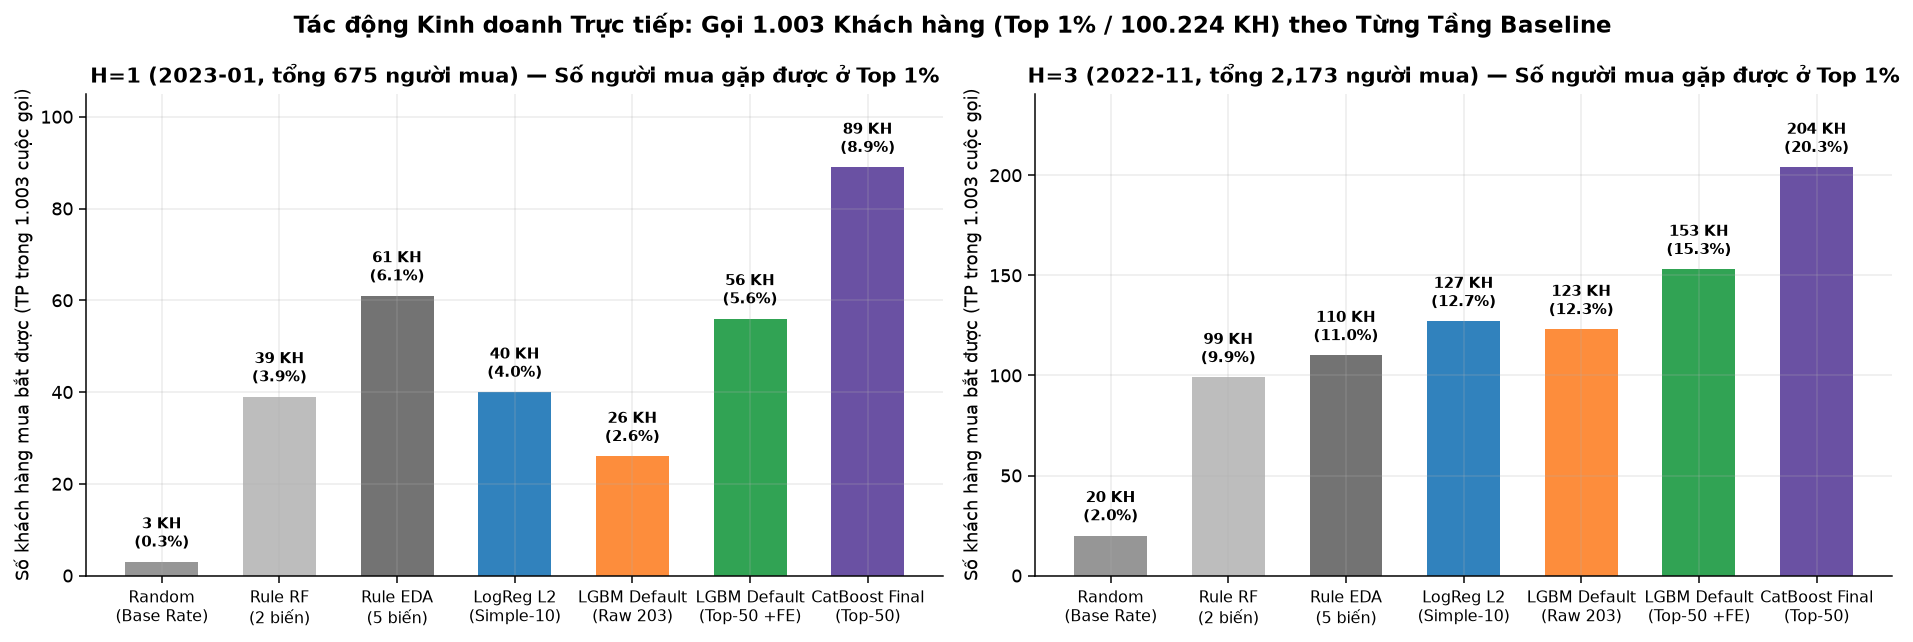

In [9]:
# Compact 5-tier Executive Report Table (exact format for management / technical report)
EXEC_TIERS = [
    ("T0_random_prevalence", "Random (Base Rate)", "mốc sàn (0 biến, p_train)"),
    ("T1a_rule_rf", "Rule RF cổ điển", "baseline business đơn giản (2 biến TRX 84d)"),
    ("T1b_rule_eda_scorecard", "Rule EDA Scorecard", "baseline business mạnh (5 biến, không ML)"),
    ("T2_logreg_simple10", "Logistic Regression (L2)", "ML cơ bản, 10 biến dễ giải thích"),
    ("T3a_lgbm_default_raw203", "LightGBM Default (Raw)", "GBDT mặc định trên 203 biến thô, chưa FE"),
    ("T3b_xgb_default_raw203", "XGBoost Default (Raw)", "GBDT mặc định trên 203 biến thô, chưa FE"),
    ("T4a_lgbm_default_top50", "LightGBM Default (+FE)", "đo đóng góp thuần của FE (50 biến)"),
    ("T5_final_catboost_top50", "Mô hình cuối (CatBoost)", "sau FE + regularization (50 biến, không SMOTE)"),
]

for h, test_m in ((1, "2023-01"), (3, "2022-11")):
    f_sub = final_df[final_df["horizon"] == h].set_index("tier_id")
    b_sub = boot_df[(boot_df["horizon"] == h) & (boot_df["scope"] == "final_holdout_panel")].set_index("tier_id")
    o_sub = boot_df[(boot_df["horizon"] == h) & (boot_df["scope"] == "final_holdout_oot_ooc")].set_index("tier_id")
    rows = []
    for tid, name, note in EXEC_TIERS:
        r = f_sub.loc[tid]
        b = b_sub.loc[tid]
        ooc_ap_str = f"{o_sub.loc[tid, 'average_precision']:.4f}" if tid in o_sub.index else "—"
        rows.append({
            "Mô hình": name,
            "PR-AUC [95% CI]": fmt_ci(b["average_precision"], b["average_precision_ci_low"], b["average_precision_ci_high"], 4),
            "PR-AUC (0% trùng KH)": ooc_ap_str,
            "ROC-AUC": f"{b['roc_auc']:.4f}",
            "Lift@1% [95% CI]": fmt_ci(b["lift_1pct"], b["lift_1pct_ci_low"], b["lift_1pct_ci_high"], 2, "×"),
            "Số KH mua / 1.003 gọi": f"{int(r['hits_1pct'])} ({r['precision_1pct']*100:.2f}%)",
            "Brier": "—" if pd.isna(r["brier"]) else f"{r['brier']:.5f}",
            "Ghi chú": note,
        })
    if h == 1:
        r = f_sub.loc["T5_final_cal_intercept"]
        b = b_sub.loc["T5_final_cal_intercept"]
        rows.append({
            "Mô hình": "Mô hình cuối + Calibration",
            "PR-AUC [95% CI]": fmt_ci(b["average_precision"], b["average_precision_ci_low"], b["average_precision_ci_high"], 4),
            "PR-AUC (0% trùng KH)": "—",
            "ROC-AUC": f"{b['roc_auc']:.4f}",
            "Lift@1% [95% CI]": fmt_ci(b["lift_1pct"], b["lift_1pct_ci_low"], b["lift_1pct_ci_high"], 2, "×"),
            "Số KH mua / 1.003 gọi": f"{int(r['hits_1pct'])} ({r['precision_1pct']*100:.2f}%)",
            "Brier": f"{r['brier']:.5f}",
            "Ghi chú": "Intercept-Shift trên 2022-12 (CalRatio 1.254 → 1.061)",
        })
    print(f"=== BẢNG BÁO CÁO CHUẨN — H={h} Final Holdout ({test_m}) | seed=42 | 1.000 Bootstrap ===")
    display(pd.DataFrame(rows))

# Chart 7: Business Impact (Buyers Captured per 1,003 Calls across the 5 main tiers)
biz_tiers = [
    ("T0_random_prevalence", "Random\n(Base Rate)"),
    ("T1a_rule_rf", "Rule RF\n(2 biến)"),
    ("T1b_rule_eda_scorecard", "Rule EDA\n(5 biến)"),
    ("T2_logreg_simple10", "LogReg L2\n(Simple-10)"),
    ("T3a_lgbm_default_raw203", "LGBM Default\n(Raw 203)"),
    ("T4a_lgbm_default_top50", "LGBM Default\n(Top-50 +FE)"),
    ("T5_final_catboost_top50", "CatBoost Final\n(Top-50)"),
]
biz_cols = ["#969696", "#bdbdbd", "#737373", "#3182bd", "#fd8d3c", "#31a354", "#6a51a3"]

fig, axes = plt.subplots(1, 2, figsize=(14.2, 4.8))
for ax, (h, test_m, tot_pos) in zip(axes, ((1, "2023-01", 675), (3, "2022-11", 2173))):
    f_sub = final_df[final_df["horizon"] == h].set_index("tier_id")
    hits = [int(f_sub.loc[t, "hits_1pct"]) for t, _ in biz_tiers]
    precs = [float(f_sub.loc[t, "precision_1pct"]) * 100 for t, _ in biz_tiers]
    x = np.arange(len(biz_tiers))
    bars = ax.bar(x, hits, color=biz_cols, width=0.62)
    ax.set_xticks(x)
    ax.set_xticklabels([lbl for _, lbl in biz_tiers], fontsize=8.3)
    ax.set_ylabel("Số khách hàng mua bắt được (TP trong 1.003 cuộc gọi)")
    ax.set_title(f"H={h} ({test_m}, tổng {tot_pos:,} người mua) — Số người mua gặp được ở Top 1%", fontweight="bold")
    ax.set_ylim(0, max(hits) * 1.18)
    for b, ht, pr in zip(bars, hits, precs):
        ax.text(b.get_x() + b.get_width() / 2, ht + max(hits) * 0.025, f"{ht} KH\n({pr:.1f}%)",
                ha="center", va="bottom", fontsize=8.1, fontweight="bold")

fig.suptitle("Tác động Kinh doanh Trực tiếp: Gọi 1.003 Khách hàng (Top 1% / 100.224 KH) theo Từng Tầng Baseline", fontsize=12.5, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_business_impact_top1pct.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Tổng kết

### Q&A
- **Mô hình phức tạp hơn thực sự mang lại bao nhiêu giá trị so với baseline không ML và ML đơn giản?**
  Trên tập Holdout khóa cứng (`seed = 42`, `100.224` khách hàng), mô hình cuối `T5_final_catboost_top50` đạt **`PR-AUC = 0,0552`**, **`Lift@1% = 13,18×`** (`89` người mua / `1.003` cuộc gọi) ở `H=1` (`2023-01`) và **`PR-AUC = 0,0913`**, **`Lift@1% = 9,38×`** (`204` người mua / `1.003` cuộc gọi, `Precision@1% = 20,34%`) ở `H=3` (`2022-11`). So với luật nghiệp vụ mạnh nhất không dùng ML (`T1b_rule_eda_scorecard`), mô hình cuối tăng gấp **1,75×** về `PR-AUC` (`0,0316 → 0,0552`) ở `H=1` và **1,55×** (`0,0587 → 0,0913`) ở `H=3`; so với Logistic Regression cơ bản (`T2_logreg_simple10`), tăng **`ΔPR-AUC = +0,0313`** (+131%, $p < 0,001$) ở `H=1` và **`+0,0253`** (+38%, $p < 0,001$) ở `H=3`.
- **Feature Engineering đóng góp bao nhiêu khi giữ nguyên thuật toán và tham số mặc định?**
  Chuyển từ `203` biến thô sạch (`raw_clean_203`) sang bộ `50` biến sau FE (`top50`) giúp **LightGBM mặc định** tăng `PR-AUC` tới **+70%** ở `H=1` (`0,0219 → 0,0372`, $p < 0,001$) và **+22%** ở `H=3` (`0,0646 → 0,0789`, $p < 0,001$); **XGBoost mặc định** cũng tăng tương ứng **+70%** ở `H=1` (`0,0192 → 0,0326`, $p < 0,001$) và **+18%** ở `H=3` (`0,0561 → 0,0662`, $p < 0,001$).
- **Khi tách rời hoàn toàn khách hàng giữa train và test (0% trùng `client_id`), kết quả có còn giữ vững không?**
  Có. Trên kiểm chứng **5-fold `OOT + OOC`** phủ trọn `100.224` khách hàng với **0% trùng khách**, `T2_logreg_simple10` hoàn toàn không đổi (`p > 0,50`), còn `T5_final_catboost_top50` giữ nguyên 100% `ROC-AUC` (`0,8158 → 0,8161` ở `H=1`; `0,7710 → 0,7708` ở `H=3`). Phần đuôi cực cao (`PR-AUC`) giảm vừa phải (`0,0552 → 0,0433` ở `H=1`; `0,0913 → 0,0845` ở `H=3`, $p < 0,001$) do không còn tận dụng nhận diện khách tái mua quen thuộc, nhưng mô hình cuối vẫn giữ vị trí số 1 vượt xa mọi baseline (`Lift@1% = 12,44×` ở `H=1` và `8,42×` ở `H=3`).

### Data Analysis Key Findings
- **Chẩn đoán `B0` pooled artifact:** Trên từng tháng đơn lẻ và Final Holdout, `T0_random_prevalence` luôn cho đúng `ROC-AUC = 0,5000` và `PR-AUC = prevalence`; giá trị `0,5179` ở báo cáo gộp 3 tháng trước đây thuần túy do `p_train` giảm dần song song với base rate thực tế.
- **GBDT mặc định trên dữ liệu thô kém cả rule nghiệp vụ và lệch xác suất:** Trên `H=1` Holdout, cả `T3a_lgbm_default_raw203` (`PR-AUC = 0,0219`, `BSS = -6,12%`) và `T3b_xgb_default_raw203` (`PR-AUC = 0,0192`, `BSS = -1,99%`) đều thua `T1b_rule_eda_scorecard` (`PR-AUC = 0,0316`) và có Brier score kém hơn hằng số `T0`, trong khi `T2_logreg_simple10` calibrate tốt hơn hẳn (`BSS = +0,57%`).
- **Tách bạch nguồn gốc giá trị:** Toàn bộ sức mạnh của `T5_final_catboost_top50` đến từ **2 trụ cột cộng hưởng**: (1) Feature Engineering chất lượng cao (`+0,0134` đến `+0,0178` `PR-AUC`, $p < 0,001$) và (2) Regularization + cấu trúc cây đối xứng chống overfit lá hiếm (`+0,0180` đến `+0,0226` `PR-AUC` so với LGBM/XGB mặc định trên cùng `Top-50`, $p \le 0,006$).
- **Hiệu chỉnh xác suất 1 tham số (`intercept_shift`)** trên tháng `2022-12` xử lý triệt để hiện tượng trượt tỷ lệ mua cuối năm của `H=1` (`Calibration Ratio: 1,254 → 1,061`, `ECE: 0,00171 → 0,00108`, `LogLoss: 0,03529 → 0,03511`, $p < 0,001$) mà không làm thay đổi thứ hạng.

### Insights or Next Steps
- **Báo cáo song hành 2 kịch bản vận hành (`Panel OOT` và `OOT + OOC`)** cho mọi vòng cải tiến mô hình tiếp theo: `Panel OOT` đại diện cho bài toán chấm điểm lại tệp khách hiện hữu hằng tháng, trong khi `OOT + OOC` đóng vai trò hàng rào kiểm soát chống overfit vào nhóm khách lặp lại ở đuôi xác suất cao.
- **Bước nâng cấp tiếp theo sau baseline:** tinh chỉnh riêng `LightGBM`/`XGBoost` có regularization mạnh (`min_child_samples` cao, `learning_rate` nhỏ, `colsample_bytree`) để so sánh công bằng với `CatBoost`, đồng thời kiểm tra việc bổ sung nhóm ~`12` biến hành vi mạnh ngoài Top-50 và embedding `DIALOG` (PCA fit trên train) dưới cùng khung kiểm định `OOT + OOC` và `Brier/LogLoss`.
